# Cross-study analyses

Every figure, table and statistic in the manuscript that combines the two studies comes from this notebook. It writes files only: figures to `study_comparison/plots/` and tables to `study_comparison/tables/`. `main.tex` includes those files and owns all document structure.

**Inputs:** `sci_fund_real/data/clean/analysis_data.csv` and `satellite/data/clean/analysis_data.csv`, plus the CSVs each study's `main_analysis.ipynb` exports to `{study}/{study}_tables/`.

## Setup

Loads both studies' cleaned data. Later cells in *Treatment effects* use the data frames defined here.

In [1]:
# Every path in this notebook is relative to the repo root. Move there first, so the notebook
# runs whether the kernel starts in study_comparison/ or in the repo root.
import os
from pathlib import Path
if not Path("src/helpers.py").exists() and Path("../src/helpers.py").exists():
    os.chdir("..")

import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../sci_fund_real'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats as sp_stats
import warnings
from sharp_q_values import compute_q

warnings.filterwarnings('ignore')

# ── Load ──────────────────────────────────────────────────────────────────────
sat = pd.read_csv('satellite/data/clean/analysis_data.csv')
sci = pd.read_csv('sci_fund_real/data/clean/analysis_data.csv')

# Harmonize control arm name
sci['treat_status'] = sci['treat_status'].replace({'control': 'vignette'})

sat['study'] = 'Satellite'
sci['study'] = 'Sci-Fund'

# Shared treat arms
ARMS = ['treat', 'vignette', 'placebo']
sat = sat[sat['treat_status'].isin(ARMS)].copy()
sci = sci[sci['treat_status'].isin(ARMS)].copy()

print(f"Satellite N={len(sat)}  treat={sat['treat_status'].eq('treat').sum()}")
print(f"Sci-Fund  N={len(sci)}  treat={sci['treat_status'].eq('treat').sum()}")

Satellite N=894  treat=298
Sci-Fund  N=1007  treat=333


# Treatment effects

## Headline effects (Figure 2)

**Output:** `headline_effects.pdf`

**Computation:** AIM-minus-control OLS contrasts with HC1 errors, by study, outcome and familiarity group. Sharpened *q* values across the 12 contrasts in each study; the table of *q* values is printed.

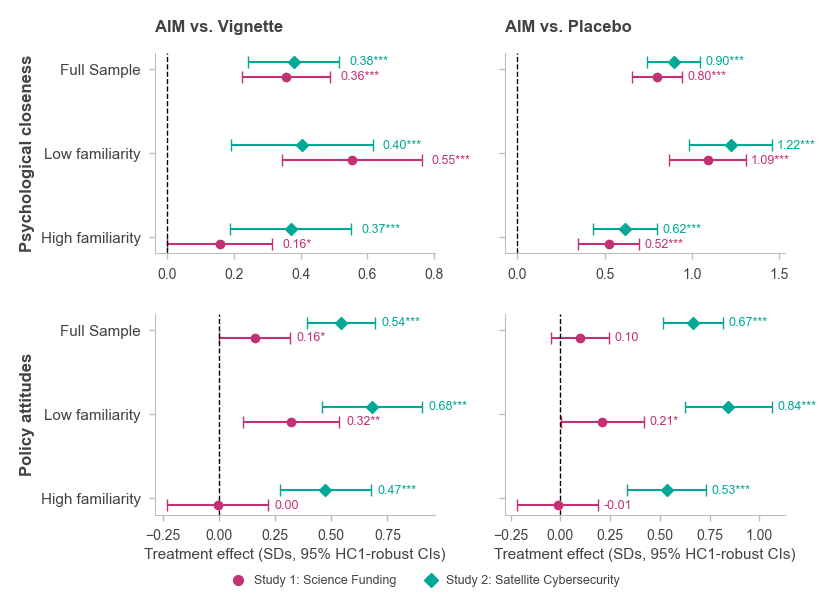

In [2]:
"""
Name: Josh Ashkinaze

Date: 2026-09-04

Description: Forest plot comparing AIM treatment effects across two studies. For each
(study, subsample, outcome) we fit one saturated regression with treat as the omitted
arm, then negate each coefficient to express the AIM advantage over that comparison arm.

Inputs:
- sci, DataFrame for Study 1 (science funding)
- sat, DataFrame for Study 2 (satellite cybersecurity)
- satellite/helpers.py, module providing make_aesthetic

Outputs:
- study_comparison_forest.pdf
"""

import sys, os
if os.path.abspath('satellite') not in sys.path:
    sys.path.insert(0, os.path.abspath('satellite'))

import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
import importlib.util as _ilu

_spec = _ilu.spec_from_file_location('helpers', os.path.abspath('satellite/helpers.py'))
_helpers = _ilu.module_from_spec(_spec)
_spec.loader.exec_module(_helpers)
make_aesthetic = _helpers.make_aesthetic

####################
# Analysis specification
####################

LOW_CUT = 2

SUBSAMPLES = {
    "Full Sample":    lambda df: df,
    "Low familiarity":  lambda df: df[df["familiar"] <= LOW_CUT],
    "High familiarity": lambda df: df[df["familiar"] > LOW_CUT],
}
SAMPLE_ORDER = ["Full Sample", "Low familiarity", "High familiarity"]

OUTCOMES = {
    "closeness_index": "Psychological closeness",
    "attitude_index":  "Policy attitudes",
}

# One saturated regression per (study, subsample, outcome):
#   dv ~ is_vignette + is_placebo
# treat is the omitted arm, so each coefficient estimates (arm - treat).
# We report the AIM advantage, (treat - arm), which is the negated coefficient.
BASELINE_ARM = "treat"
COMPARISON_ARMS = {
    "vignette": "AIM vs. Vignette",
    "placebo":  "AIM vs. Placebo",
}
ARM_DUMMIES = {arm: f"is_{arm}" for arm in COMPARISON_ARMS}
MODEL_RHS = " + ".join(ARM_DUMMIES.values())
ALL_ARMS = [BASELINE_ARM, *COMPARISON_ARMS]

# Sharpened FDR q-value thresholds for the star annotations
Q_STARS = [(0.001, "***"), (0.01, "**"), (0.05, "*")]


def stars(q):
    """Stars for a sharpened q-value: *** q<=.001, ** q<=.01, * q<=.05, blank otherwise."""
    for cutoff, mark in Q_STARS:
        if q <= cutoff:
            return mark
    return ""

STUDIES = [
    (sci, "Study 1: Science Funding",         "o", "#C13174"),
    (sat, "Study 2: Satellite Cybersecurity", "D", "#00A896"),
]

####################
# Estimation
####################


def add_arm_dummies(df):
    """Add one 0/1 column per comparison arm; the baseline arm gets no column."""
    df = df.copy()
    for arm, dummy_name in ARM_DUMMIES.items():
        df[dummy_name] = (df["treat_status"] == arm).astype(int)
    return df


def flip_to_aim_advantage(fit, dummy_name):
    """Negate one coefficient and its CI to give (treat - arm) instead of (arm - treat).

    Negation reverses the interval, so the negated upper bound becomes the lower
    bound. The p-value is symmetric and passes through unchanged.
    """
    lower_bound, upper_bound = fit.conf_int().loc[dummy_name]
    return dict(
        beta=-fit.params[dummy_name],
        ci_lo=-upper_bound,
        ci_hi=-lower_bound,
        p=fit.pvalues[dummy_name],
    )


rows = []
for sample_name in SAMPLE_ORDER:
    for study_df, study_label, marker, color in STUDIES:
        analysis_sample = SUBSAMPLES[sample_name](study_df)
        analysis_sample = analysis_sample[analysis_sample["treat_status"].isin(ALL_ARMS)]
        analysis_sample = add_arm_dummies(analysis_sample)

        for outcome, outcome_label in OUTCOMES.items():
            estimation_sample = analysis_sample.dropna(subset=[outcome])
            fit = smf.ols(f"{outcome} ~ {MODEL_RHS}", data=estimation_sample).fit(cov_type="HC1")

            for arm, contrast_label in COMPARISON_ARMS.items():
                rows.append(dict(
                    contrast=contrast_label, sample=sample_name, kind=study_label,
                    outcome=outcome_label, color=color,
                    **flip_to_aim_advantage(fit, ARM_DUMMIES[arm]),
                ))

forest_df = pd.DataFrame(rows)

# Each study is one family of hypotheses (Anderson 2008 sharpened q-values)
for study_label, study_rows in forest_df.groupby("kind"):
    forest_df.loc[study_rows.index, "q_sharp"] = compute_q(study_rows["p"].values)
forest_df["stars"] = forest_df["q_sharp"].map(stars)

####################
# Plot
####################

DODGE_SPACING = 0.18
LABEL_OFFSET = 0.03

study_labels = [study[1] for study in STUDIES]
markers = {study[1]: study[2] for study in STUDIES}
dodges = {
    label: (i - (len(study_labels) - 1) / 2) * DODGE_SPACING
    for i, label in enumerate(study_labels)
}

pal = make_aesthetic(smallest_font_size=10, with_ticks=True)
plt.rcParams['figure.constrained_layout.use'] = False

outcome_labels = list(OUTCOMES.values())
contrast_labels = list(COMPARISON_ARMS.values())
row_positions = {"High familiarity": 0, "Low familiarity": 1, "Full Sample": 2}

fig, axes = plt.subplots(len(outcome_labels), len(contrast_labels), figsize=(9, 6), sharey=True)
axes = np.atleast_2d(axes)

for row_i, outcome_label in enumerate(outcome_labels):
    for col_i, contrast_label in enumerate(contrast_labels):
        ax = axes[row_i, col_i]
        panel = forest_df[
            (forest_df["outcome"] == outcome_label) &
            (forest_df["contrast"] == contrast_label)
        ]

        for _, estimate in panel.iterrows():
            y = row_positions[estimate["sample"]] + dodges[estimate["kind"]]
            color = estimate["color"]
            ax.errorbar(
                estimate["beta"], y,
                xerr=[[estimate["beta"] - estimate["ci_lo"]],
                      [estimate["ci_hi"] - estimate["beta"]]],
                fmt=markers[estimate["kind"]], color=color, ecolor=color,
                markerfacecolor=color, markeredgecolor=color,
                capsize=4, markersize=6, linewidth=1.5,
            )
            value = f"{estimate['beta']:.2f}".replace("-0.00", "0.00")
            ax.text(
                estimate["ci_hi"] + LABEL_OFFSET, y,
                f"{value}{estimate['stars']}",
                va="center", ha="left", fontsize=9, color=color,
            )

        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks(list(row_positions.values()))
        if col_i == 0:
            ax.set_yticklabels(list(row_positions.keys()), fontsize=11)
            ax.set_ylabel(outcome_label, fontsize=12, fontweight="bold")
        else:
            ax.tick_params(labelleft=False)
        if row_i == len(outcome_labels) - 1:
            ax.set_xlabel("Treatment effect (SDs, 95% HC1-robust CIs)", fontsize=11)
        if row_i == 0:
            ax.set_title(contrast_label, fontsize=12, fontweight="bold")
        ax.spines[["top", "right"]].set_visible(False)

handles = [
    mlines.Line2D([], [], color=color, marker=marker, linestyle="None",
                  markersize=7, markerfacecolor=color, label=label)
    for _, label, marker, color in STUDIES
]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9,
           bbox_to_anchor=(0.5, -0.04), frameon=False)

plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)
from pathlib import Path
Path('study_comparison/plots').mkdir(parents=True, exist_ok=True)
plt.savefig("study_comparison/plots/headline_effects.pdf", bbox_inches="tight")
plt.show()

## Covariate-adjusted effects, Lin estimator

**Output:** `study_comparison_forest_adjusted.pdf`

**Computation:** demeaned covariates interacted with the treatment indicators (Lin 2013).

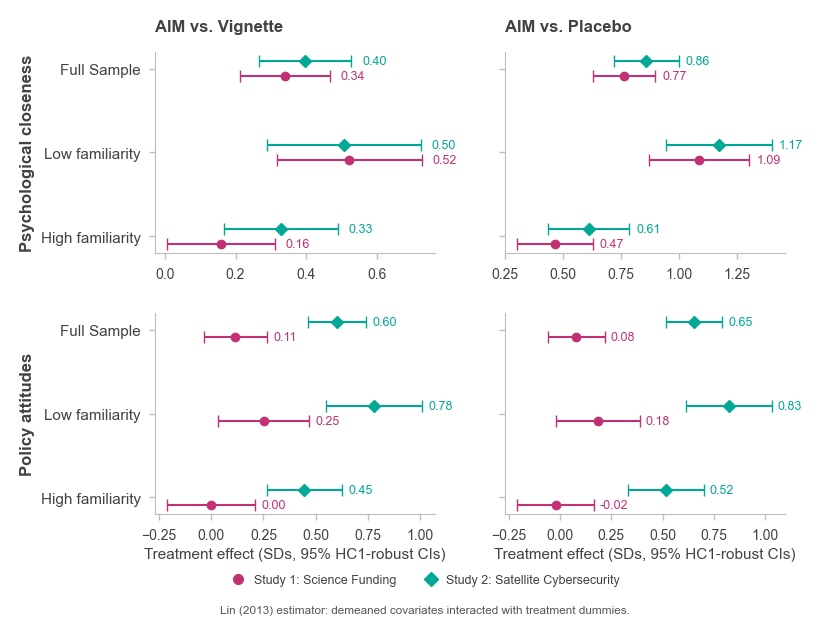

In [3]:
####################
# Covariate-adjusted forest plot — Lin (2013) estimator
# Demean each covariate, then interact with treatment dummies.
# Formula: dv ~ is_vignette + is_placebo + cov_dm + ... + is_vignette:cov_dm + is_placebo:cov_dm + ...
####################

COVS = [
    "familiar", "mi_index", "iri_fa", "iri_pc", "iri_pd",
    "rw_journal", "rw_write", "age", "educ_num", "income_num",
    "gender_male", "ai_attitude_index",
]
COVS_DM = [f"{c}_dm" for c in COVS]


def lin_formula(covs_dm):
    """Build the Lin (2013) covariate-adjustment formula."""
    main = " + ".join(covs_dm)
    inter = " + ".join(
        f"is_vignette:{c} + is_placebo:{c}" for c in covs_dm
    )
    return f"{MODEL_RHS} + {main} + {inter}"


adj_rows = []

for sample_name in SAMPLE_ORDER:
    for study_df, study_label, marker, color in STUDIES:
        analysis_sample = SUBSAMPLES[sample_name](study_df)
        analysis_sample = analysis_sample[
            analysis_sample["treat_status"].isin(ALL_ARMS)
        ]
        analysis_sample = add_arm_dummies(analysis_sample)

        for outcome, outcome_label in OUTCOMES.items():
            est_samp = analysis_sample.dropna(
                subset=[outcome] + COVS
            ).copy()

            # Demean each covariate on this estimation sample.
            for covariate, covariate_dm in zip(COVS, COVS_DM):
                est_samp[covariate_dm] = (
                    est_samp[covariate] - est_samp[covariate].mean()
                )

            formula = f"{outcome} ~ {lin_formula(COVS_DM)}"
            fit = smf.ols(
                formula,
                data=est_samp,
            ).fit(cov_type="HC1")

            for arm, contrast_label in COMPARISON_ARMS.items():
                adj_rows.append(
                    dict(
                        contrast=contrast_label,
                        sample=sample_name,
                        kind=study_label,
                        outcome=outcome_label,
                        color=color,
                        marker=marker,
                        **flip_to_aim_advantage(
                            fit,
                            ARM_DUMMIES[arm],
                        ),
                    )
                )

adj_df = pd.DataFrame(adj_rows)

####################
# Plot
####################

_outcome_labels = list(OUTCOMES.values())
_contrast_labels = list(COMPARISON_ARMS.values())

_row_positions = {
    "High familiarity": 0,
    "Low familiarity": 1,
    "Full Sample": 2,
}

_study_labels = [study[1] for study in STUDIES]
_markers = {study[1]: study[2] for study in STUDIES}

_DODGE_SPACING = 0.18
_LABEL_OFFSET = 0.03

_dodges = {
    label: (
        index - (len(_study_labels) - 1) / 2
    ) * _DODGE_SPACING
    for index, label in enumerate(_study_labels)
}

plt.rcParams.update({
    "figure.constrained_layout.use": False,
})

fig, axes = plt.subplots(
    len(_outcome_labels),
    len(_contrast_labels),
    figsize=(9, 6),
    sharey=True,
    constrained_layout=False,
)

axes = np.atleast_2d(axes)

for row_i, outcome_label in enumerate(_outcome_labels):
    for col_i, contrast_label in enumerate(_contrast_labels):
        ax = axes[row_i, col_i]

        panel = adj_df[
            (adj_df["outcome"] == outcome_label)
            & (adj_df["contrast"] == contrast_label)
        ]

        for _, est in panel.iterrows():
            y = (
                _row_positions[est["sample"]]
                + _dodges[est["kind"]]
            )

            color = est["color"]

            ax.errorbar(
                est["beta"],
                y,
                xerr=[
                    [est["beta"] - est["ci_lo"]],
                    [est["ci_hi"] - est["beta"]],
                ],
                fmt=_markers[est["kind"]],
                color=color,
                ecolor=color,
                markerfacecolor=color,
                markeredgecolor=color,
                capsize=4,
                markersize=6,
                linewidth=1.5,
            )

            ax.text(
                est["ci_hi"] + _LABEL_OFFSET,
                y,
                f"{est['beta']:.2f}".replace("-0.00", "0.00"),
                va="center",
                ha="left",
                fontsize=9,
                color=color,
            )



        ax.set_yticks(list(_row_positions.values()))

        if col_i == 0:
            ax.set_yticklabels(
                list(_row_positions.keys()),
                fontsize=11,
            )
            ax.set_ylabel(
                outcome_label,
                fontsize=12,
                fontweight="bold",
            )
        else:
            ax.tick_params(labelleft=False)

        if row_i == len(_outcome_labels) - 1:
            ax.set_xlabel(
                "Treatment effect (SDs, 95% HC1-robust CIs)",
                fontsize=11,
            )

        if row_i == 0:
            ax.set_title(
                contrast_label,
                fontsize=12,
                fontweight="bold",
            )

        ax.spines[["top", "right"]].set_visible(False)

handles = [
    mlines.Line2D(
        [],
        [],
        color=study[3],
        marker=study[2],
        linestyle="None",
        markersize=7,
        markerfacecolor=study[3],
        label=study[1],
    )
    for study in STUDIES
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=2,
    fontsize=9,
    bbox_to_anchor=(0.5, -0.04),
    frameon=False,
)

fig.text(
    0.5,
    -0.055,
    "Lin (2013) estimator: demeaned covariates interacted with treatment dummies.",
    ha="center",
    fontsize=8.5,
    color="#555555",
)

plt.subplots_adjust(
    left=0.2,
    wspace=0.25,
    hspace=0.30,
)

plt.savefig(
    "study_comparison_forest_adjusted.pdf",
    bbox_inches="tight",
)

from IPython.display import display as _disp

_disp(fig)
plt.close(fig)

## Quantile effects (Figure 3)

**Output:** `quantile_effects.pdf`

**Computation:** quantile regressions of each outcome on treatment at quantiles 0.1 to 0.9, AIM against each control.

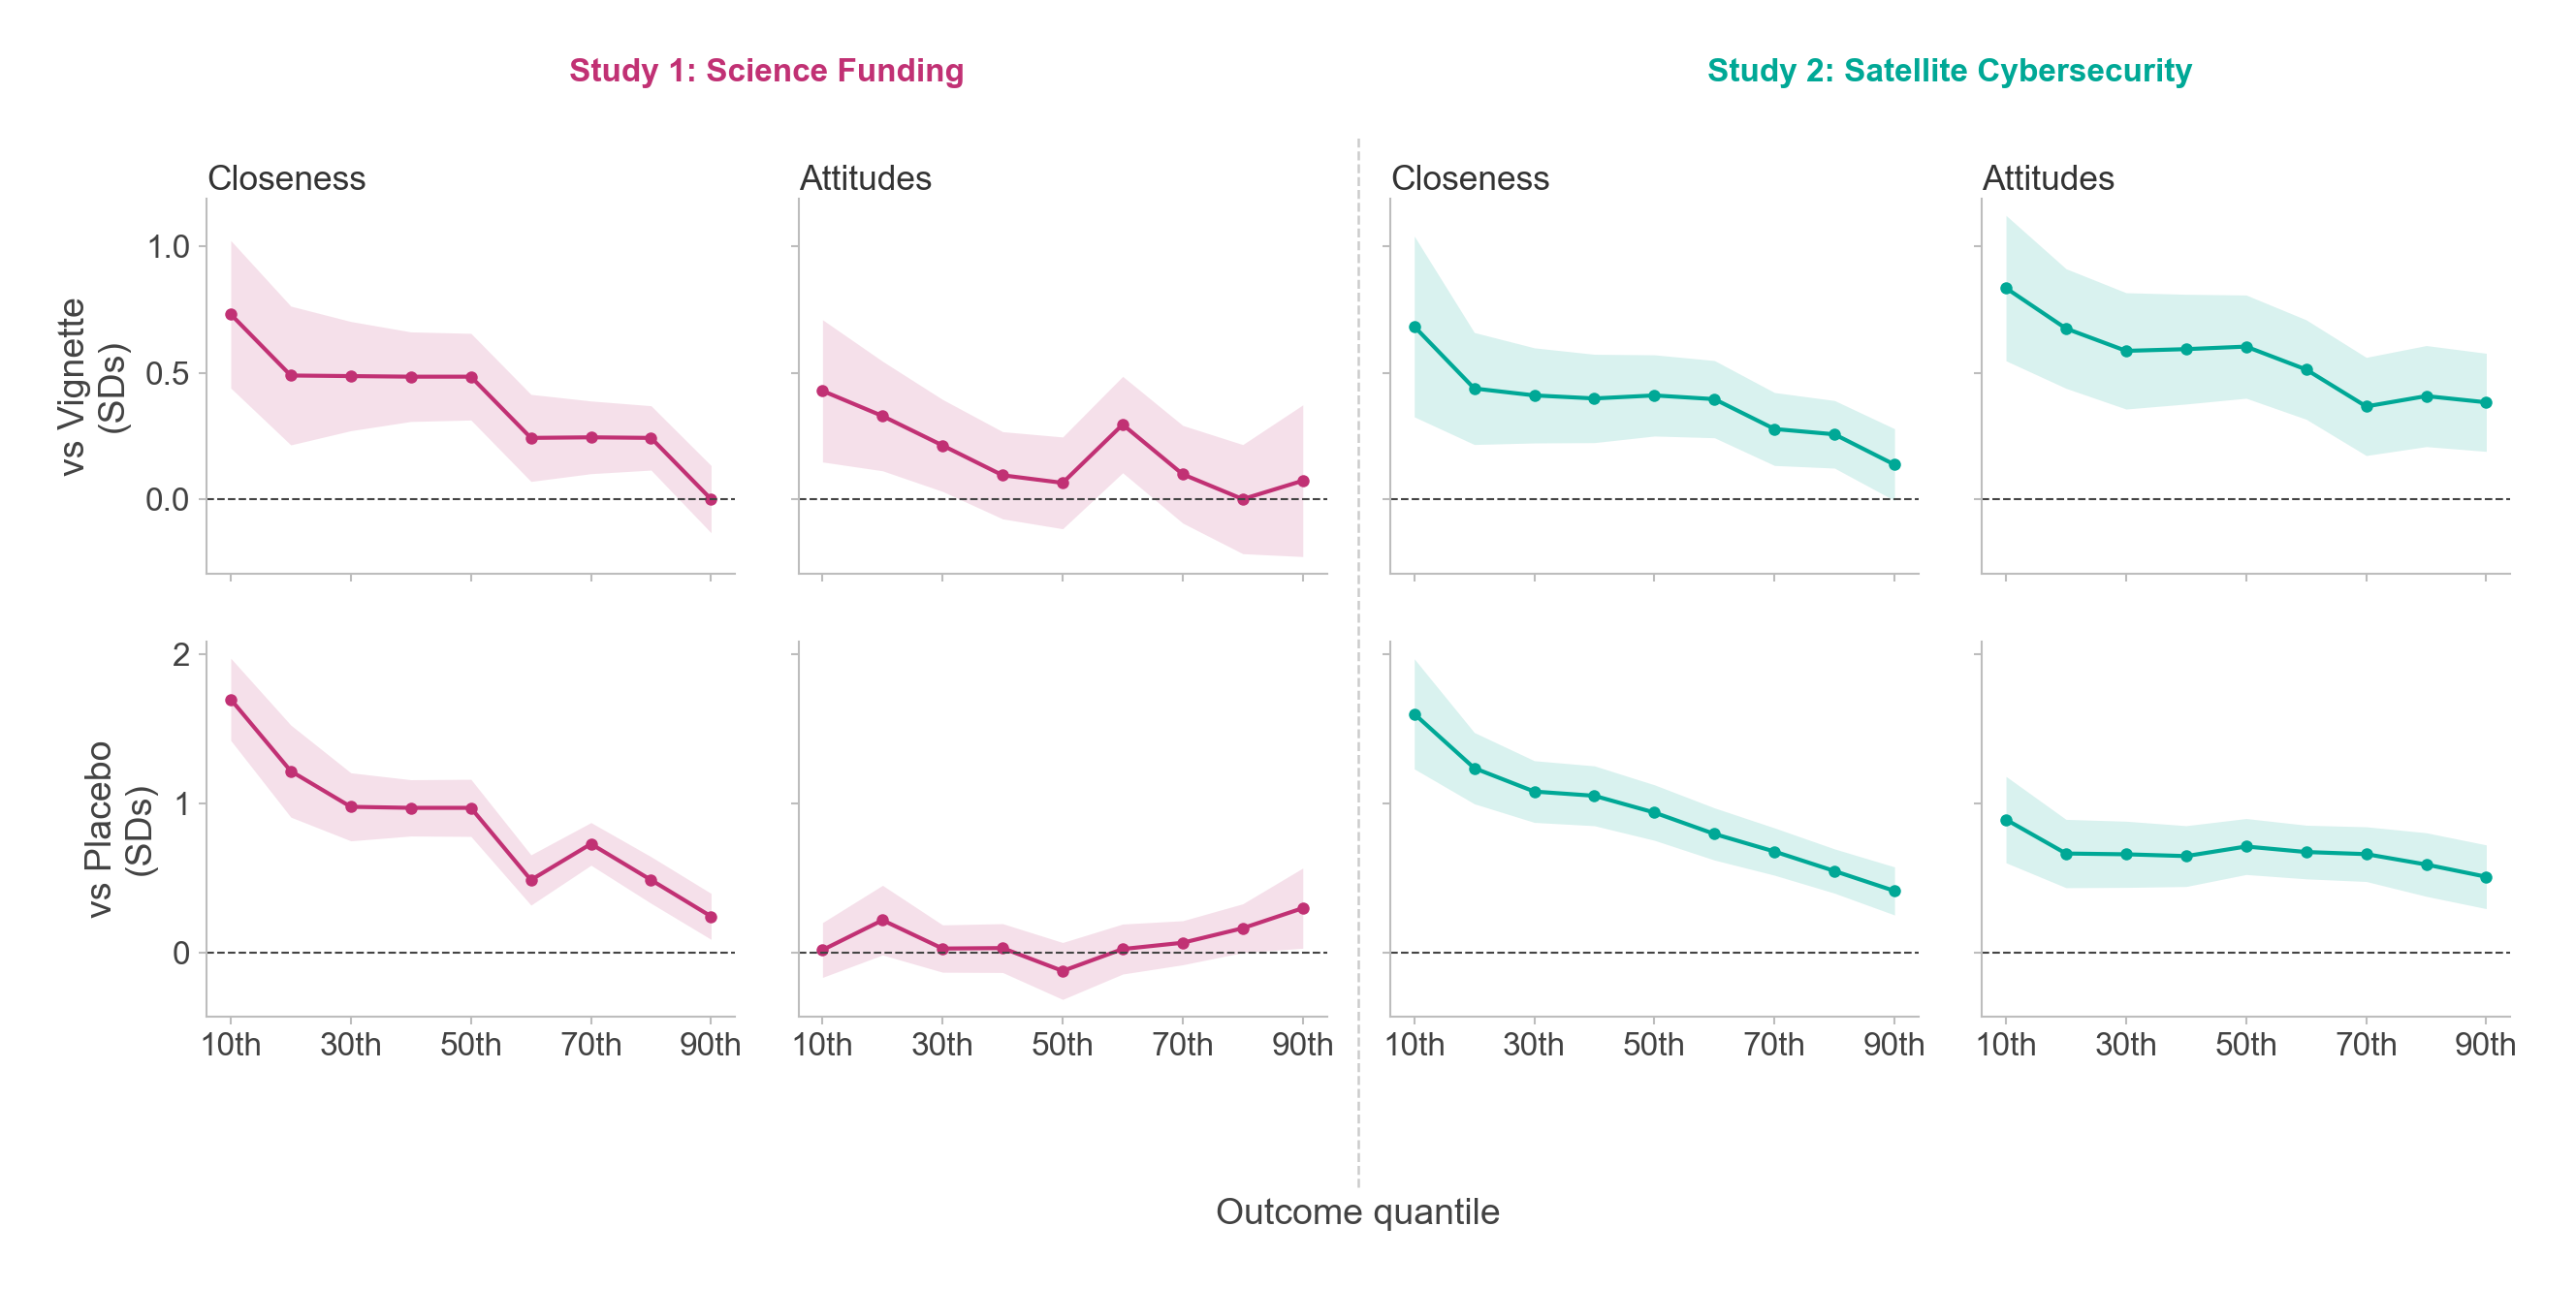

In [4]:
####################
# Quantile treatment effects — Nature-style small multiples
# Rows: vs Vignette (top) / vs Placebo (bottom)
# Cols: Science Funding × (Closeness, Attitudes) | Satellite × (Closeness, Attitudes)
####################

import matplotlib as mpl
make_aesthetic(smallest_font_size=9, with_ticks=True)
plt.rcParams['figure.constrained_layout.use'] = False

TAUS = np.arange(0.1, 1.0, 0.1)
_contrasts = [("vignette", "vs Vignette"), ("placebo", "vs Placebo")]
_outcomes  = [("closeness_index", "Closeness"), ("attitude_index", "Attitudes")]

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2,
    "lines.linewidth": 1.0, "lines.markersize": 3, "figure.dpi": 300,
})

n_rows = len(_contrasts)
n_cols = len(STUDIES) * len(_outcomes)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(9, 4.2),
                         sharey="row", sharex=True)
plt.subplots_adjust(wspace=0.12, hspace=0.18, left=0.10, right=0.98, top=0.85, bottom=0.18)

for row_i, (comp, comp_label) in enumerate(_contrasts):
    col_i = 0
    for study_df, study_label, marker, color in STUDIES:
        for outcome, outcome_label in _outcomes:
            ax = axes[row_i, col_i]
            sub = study_df[study_df["treat_status"].isin(["treat", comp])].copy()
            sub["is_treat"] = (sub["treat_status"] == "treat").astype(int)
            sub = sub.dropna(subset=[outcome, "is_treat"])

            betas, ci_lo, ci_hi = [], [], []
            for tau in TAUS:
                qr = smf.quantreg(f"{outcome} ~ is_treat", data=sub).fit(q=tau, max_iter=10000, vcov="robust")
                b  = qr.params["is_treat"]
                ci = qr.conf_int().loc["is_treat"]
                betas.append(b); ci_lo.append(ci[0]); ci_hi.append(ci[1])

            betas = np.array(betas); ci_lo = np.array(ci_lo); ci_hi = np.array(ci_hi)

            ax.fill_between(TAUS, ci_lo, ci_hi, alpha=0.15, color=color, linewidth=0)
            ax.plot(TAUS, betas, "-o", color=color, markersize=3, linewidth=1.0, markeredgewidth=0)
            ax.axhline(0, color="#444444", linestyle="--", linewidth=0.5)
            ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9])
            if row_i == n_rows - 1:
                ax.set_xticklabels(["10th", "30th", "50th", "70th", "90th"], fontsize=8)
            else:
                ax.set_xticklabels([])
            if col_i == 0:
                ax.set_ylabel(f"{comp_label}\n(SDs)", fontsize=9)
            if row_i == 0:
                ax.set_title(outcome_label, fontsize=8.5, pad=2, color="#333333")
            ax.spines[["top", "right"]].set_visible(False)
            ax.spines["left"].set_linewidth(0.5)
            ax.spines["bottom"].set_linewidth(0.5)
            ax.tick_params(axis="both", length=2, width=0.5, pad=2)
            col_i += 1

# study super-titles
for si, (_, study_label, _, color) in enumerate(STUDIES):
    c0 = axes[0, si * 2].get_position()
    c1 = axes[0, si * 2 + 1].get_position()
    fig.text((c0.x0 + c1.x1) / 2, 0.94, study_label, ha="center", va="bottom",
             fontsize=8, fontweight="bold", color=color)

# divider between studies
div_x = (axes[0, 1].get_position().x1 + axes[0, 2].get_position().x0) / 2
fig.add_artist(plt.Line2D([div_x, div_x], [0.04, 0.90],
               transform=fig.transFigure, color="#CCCCCC", linewidth=0.6, linestyle="--"))

fig.text(0.54, 0.01, "Outcome quantile", ha="center", fontsize=9)

plt.savefig("study_comparison/plots/quantile_effects.pdf", bbox_inches="tight")
from IPython.display import display as _disp
_disp(fig)
plt.close(fig)

## Raw versus covariate-adjusted effects

**Output:** `study_comparison_adjusted.pdf`

**Computation:** the AIM-minus-vignette effect with and without pretreatment covariates.

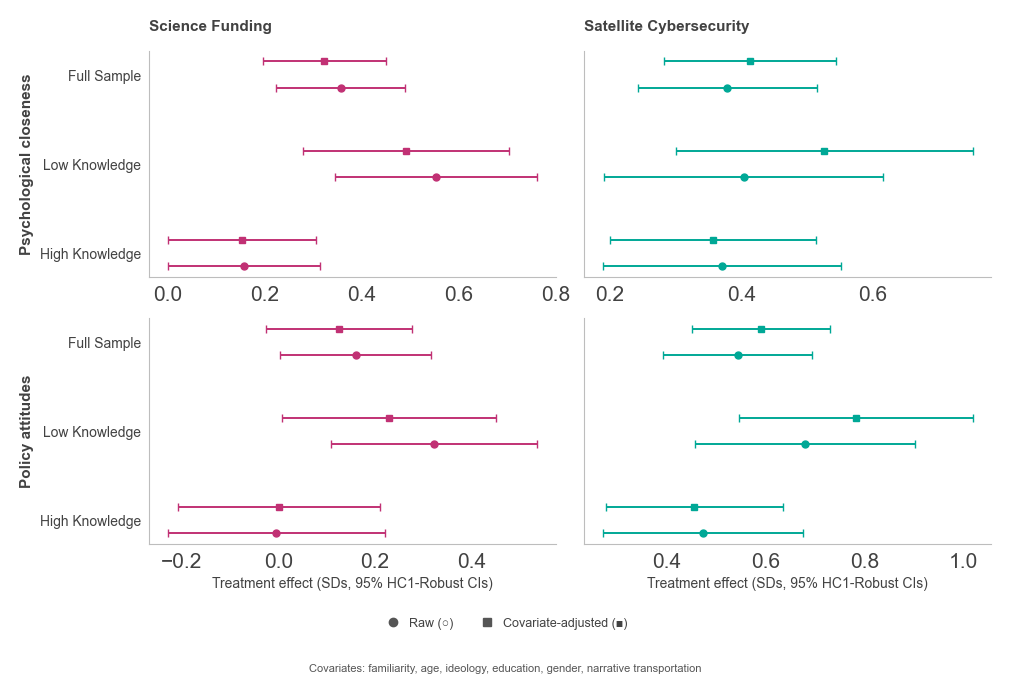

In [5]:
####################
# Headline effects: raw vs. covariate-adjusted
# Shows how much the AIM vs. Vignette effect changes once we partial out
# pre-treatment characteristics shared across both studies.
# Covariates: familiar, age, ideology, education, gender, transportation (narrative absorption)
####################

import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from helpers import make_aesthetic
from sharp_q_values import compute_q
import importlib.util as _ilu
_spec = _ilu.spec_from_file_location('helpers', os.path.abspath('satellite/helpers.py'))
_helpers = _ilu.module_from_spec(_spec); _spec.loader.exec_module(_helpers)
make_aesthetic = _helpers.make_aesthetic

make_aesthetic()

COVS = [    'familiar', 'mi_index', 'iri_fa', 'iri_pc', 'iri_pd',
    'rw_journal', 'rw_write', 'age', 'educ_num', 'income_num',
    'gender_male', 'ai_attitude_index', "ideo", 'pid3', 'blah', 'demos_7pt']
COMP_ARM   = "vignette"
SAMPLE_ORDER_H = ["Full Sample", "Low Knowledge", "High Knowledge"]
LOW_CUT_H      = 2

SUBSAMPLES_H = {
    "Full Sample":    lambda df: df,
    "Low Knowledge":  lambda df: df[df["familiar"] <= LOW_CUT_H],
    "High Knowledge": lambda df: df[df["familiar"] > LOW_CUT_H],
}

def run_both(sub, outcome, covs):
    sub = sub[sub["treat_status"].isin(["treat", COMP_ARM])].copy()
    sub["is_treat"] = (sub["treat_status"] == "treat").astype(int)
    avail = [c for c in covs if c in sub.columns and sub[c].notna().mean() > 0.5]
    sub2  = sub.dropna(subset=[outcome, "is_treat"])

    fit_raw = smf.ols(f"{outcome} ~ is_treat", data=sub2).fit(cov_type="HC1")
    b_raw   = fit_raw.params["is_treat"]
    ci_raw  = fit_raw.conf_int().loc["is_treat"]
    p_raw   = fit_raw.pvalues["is_treat"]

    cov_str  = " + ".join(avail)
    sub3     = sub2.dropna(subset=avail)
    fit_adj  = smf.ols(f"{outcome} ~ is_treat + {cov_str}", data=sub3).fit(cov_type="HC1")
    b_adj    = fit_adj.params["is_treat"]
    ci_adj   = fit_adj.conf_int().loc["is_treat"]
    p_adj    = fit_adj.pvalues["is_treat"]

    return dict(b_raw=b_raw, ci_raw=ci_raw, p_raw=p_raw,
                b_adj=b_adj, ci_adj=ci_adj, p_adj=p_adj, n=len(sub3))

# Collect
rows = []
for ss_name in SAMPLE_ORDER_H:
    subsetter = SUBSAMPLES_H[ss_name]
    for df_study, slabel, marker, color in STUDIES:
        sub = subsetter(df_study)
        for outcome, olabel in OUTCOMES.items():
            r = run_both(sub, outcome, COVS)
            rows.append(dict(sample=ss_name, study=slabel, color=color,
                             outcome=olabel, **r))

rdf_h = pd.DataFrame(rows)

# Sharp-q by study on adjusted p-values
for study_name, grp in rdf_h.groupby("study"):
    rdf_h.loc[grp.index, "q_adj"] = compute_q(grp["p_adj"].values)
    rdf_h.loc[grp.index, "q_raw"] = compute_q(grp["p_raw"].values)

# ── Plot ──────────────────────────────────────────────────────────────────────
KINDS = ["Raw", "Adjusted"]
_dodge_h = {"Raw": -0.15, "Adjusted": 0.15}
_markers_h = {"Raw": "o", "Adjusted": "s"}

y_ticks_h = {"High Knowledge": 0, "Low Knowledge": 1, "Full Sample": 2}
y_labels_h = ["High Knowledge", "Low Knowledge", "Full Sample"]
outcomes_h  = list(OUTCOMES.values())
contrasts_h = list(OUTCOMES.values())  # one col per outcome this time — rows = studies

fig, axes = plt.subplots(len(outcomes_h), 2, figsize=(10, 6), sharey=True)
axes = np.atleast_2d(axes)

for row_i, outcome in enumerate(outcomes_h):
    for col_i, (df_study, slabel, marker, color) in enumerate(STUDIES):
        ax  = axes[row_i, col_i]
        sub = rdf_h[(rdf_h["outcome"] == outcome) & (rdf_h["study"] == slabel)]

        for _, r in sub.iterrows():
            y_base = y_ticks_h[r["sample"]]
            for kind, b, ci, q_col in [
                ("Raw",      r["b_raw"], r["ci_raw"], r["q_raw"]),
                ("Adjusted", r["b_adj"], r["ci_adj"], r["q_adj"]),
            ]:
                y     = y_base + _dodge_h[kind]
                sig   = q_col < 0.05
                alpha = 1.0
                mfc   = color
                ax.errorbar(
                    b, y,
                    xerr=[[b - ci[0]], [ci[1] - b]],
                    fmt=_markers_h[kind], color=color, ecolor=color,
                    markerfacecolor=mfc, markeredgecolor=color,
                    alpha=alpha, capsize=3, markersize=5, linewidth=1.4,
                )

        ax.set_yticks([0, 1, 2])
        if col_i == 0:
            ax.set_yticklabels(y_labels_h, fontsize=10)
            ax.set_ylabel(outcome, fontsize=11, fontweight="bold")
        else:
            ax.tick_params(labelleft=False)
        if row_i == 0:
            ax.set_title(slabel.split(":")[1].strip(), fontsize=11, fontweight="bold")
        if row_i == len(outcomes_h) - 1:
            ax.set_xlabel("Treatment effect (SDs, 95% HC1-Robust CIs)", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)

import matplotlib.lines as mlines
handles = [
    mlines.Line2D([], [], color="#555", marker="o", linestyle="None",
                  markerfacecolor="#555", markersize=6, label="Raw (○)"),
    mlines.Line2D([], [], color="#555", marker="s", linestyle="None",
                  markerfacecolor="#555", markersize=6, label="Covariate-adjusted (■)"),

]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.07), frameon=False)
fig.text(0.5, -0.11,
         f"Covariates: familiarity, age, ideology, education, gender, narrative transportation",
         ha="center", fontsize=8, color="#555")

plt.tight_layout()
plt.savefig("study_comparison_adjusted.pdf", bbox_inches="tight")
plt.show()

# Manuscript tables and reported statistics

## Reported statistics, mediation and familiarity tables

**Outputs:** `results.tex` (number macros used in the text), `mediation.tex`, `familiarity_2.tex`, `familiarity_3.tex`

**Inputs:** each study's exported effect and mediation CSVs.

In [6]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08
Description: Export Nature manuscript statistics from the two clean study frames.

Inputs:
    - sci, sat: Data frames loaded in 3_study_comparison.ipynb.
Outputs:
    - study_comparison/tables/: Exact model estimates and manuscript tables.
    - study_comparison/tables/results.tex: LaTeX commands for primary results.
Notes: Primary, mediation, and binary familiarity specifications follow the supplied registrations.
"""

from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import pingouin as pg

EXPORT_DIR = Path('study_comparison/tables')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
BOOTSTRAP_DRAWS = 5000
RANDOM_SEED = 42
STUDY_FRAMES = {'Science': sci.copy(), 'Satellite': sat.copy()}
OUTCOME_NAMES = {'closeness_index': 'Closeness', 'attitude_index': 'Attitudes'}

###############
# Statistical formatting
###############
def p_latex(value):
    """Format a two-sided probability without rounding small values to zero."""
    if value < .001:
        mantissa, exponent = f'{value:.2e}'.split('e')
        return rf'{mantissa}\times 10^{{{int(exponent)}}}'
    return f'{value:.3f}'.removeprefix("0")

def table_p_latex(value):
    """Retain three significant digits and render probabilities in LaTeX."""
    formatted = f"{value:.3g}"
    if "e" in formatted:
        mantissa, exponent = formatted.split("e")
        return rf"${mantissa}\times10^{{{int(exponent)}}}$"
    if formatted.startswith("0."):
        formatted = formatted[1:]
    return "$" + formatted + "$"

def model_row(fit, term, sign=1):
    """Extract a coefficient and its confidence interval in the requested direction."""
    bounds = sorted(sign * fit.conf_int().loc[term].to_numpy())
    return {'b': sign * fit.params[term], 'se': fit.bse[term],
            'lo': bounds[0], 'hi': bounds[1], 'p': fit.pvalues[term],
            'z': sign * fit.tvalues[term], 'n': int(fit.nobs)}

###############
# Primary effects, familiarity, mediation, and preregistered familiarity moderation
###############
effects, interactions, mediations, counts = [], [], [], []
for study_name, frame in STUDY_FRAMES.items():
    frame['is_vignette'] = frame.treat_status.eq('vignette').astype(int)
    frame['is_placebo'] = frame.treat_status.eq('placebo').astype(int)
    for arm, group in frame.groupby('treat_status'):
        counts.append({'study': study_name, 'arm': arm, 'n': len(group),
                       'familiar_mean': group.familiar.mean()})
    for cutoff in [2, 3]:
        frame['low'] = (frame.familiar <= cutoff).astype(float).where(frame.familiar.notna())
        groups = {'Full': frame, 'Low': frame[frame.low.eq(1)], 'High': frame[frame.low.eq(0)]}
        for outcome, outcome_name in OUTCOME_NAMES.items():
            for group_name, subset in groups.items():
                fit = smf.ols(f'{outcome} ~ is_vignette + is_placebo', data=subset).fit(cov_type='HC1')
                for control in ['vignette', 'placebo']:
                    effects.append({'study': study_name, 'outcome': outcome_name,
                                    'cutoff': cutoff, 'sample': group_name, 'control': control,
                                    **model_row(fit, f'is_{control}', -1)})
            fit = smf.ols(f'{outcome} ~ (is_vignette + is_placebo) * low', data=frame).fit(cov_type='HC1')
            for control in ['vignette', 'placebo']:
                interactions.append({'study': study_name, 'outcome': outcome_name,
                                     'cutoff': cutoff, 'control': control,
                                     **model_row(fit, f'is_{control}:low', -1)})
    for control in ['vignette', 'placebo']:
        pair = frame[frame.treat_status.isin(['treat', control])].copy()
        pair['is_treat'] = pair.treat_status.eq('treat').astype(int)
        med_data = pair[['is_treat', 'closeness_index', 'attitude_index']].dropna()
        med = pg.mediation_analysis(data=med_data, x='is_treat', m='closeness_index',
                                   y='attitude_index', n_boot=BOOTSTRAP_DRAWS, seed=RANDOM_SEED)
        med['study'], med['control'], med['n'] = study_name, control, len(med_data)
        mediations.append(med)

effect_table = pd.DataFrame(effects)
interaction_table = pd.DataFrame(interactions)


# Sharpened q-values: each study's eight preregistered interaction tests
# (2 outcomes x 2 controls x 2 familiarity cutoffs) form one family
interaction_table['q'] = interaction_table.groupby('study')['p'].transform(lambda p: compute_q(p.values))
print("Familiarity moderation (additional AIM effect among low-familiarity participants):")
print(interaction_table[['study', 'outcome', 'cutoff', 'control', 'b', 'lo', 'hi', 'p', 'q']].round(3).to_string(index=False))
mediation_table = pd.concat(mediations, ignore_index=True)
for name, table in [('effects', effect_table), ('familiarity_interactions', interaction_table),
                    ('mediation', mediation_table),
                    ('sample_sizes', pd.DataFrame(counts))]:
    table.to_csv(EXPORT_DIR / f'{name}.csv', index=False)

###############
# LaTeX output
###############
commands = []
for row in effect_table[(effect_table.cutoff == 2) & (effect_table['sample'] == 'Full')].itertuples():
    key = row.study + row.outcome + row.control.title()
    value = rf'\beta={row.b:.2f}$ SDs, $95\%$ CI $[{row.lo:.2f}, {row.hi:.2f}]$, $p={p_latex(row.p)}'
    commands.append(rf'\newcommand{{\{key}}}{{${value}$}}')
Path('study_comparison/tables/results.tex').write_text('\n'.join(commands) + '\n')

for cutoff in [2, 3]:
    table = effect_table[(effect_table.cutoff == cutoff) & (effect_table['sample'] != 'Full')].copy()
    table['Effect [95\\% CI]'] = table.apply(lambda r: f'{r.b:.2f} [{r.lo:.2f}, {r.hi:.2f}]', axis=1)
    table['$p$'] = table.p.map(lambda p: '$' + p_latex(p) + '$')
    table = table[['study', 'outcome', 'sample', 'control', 'n', 'Effect [95\\% CI]', '$p$']]
    table.to_latex(EXPORT_DIR / f'familiarity_{cutoff}.tex', index=False, escape=False,
                   column_format='llllrrr', caption=rf'Familiarity split at {cutoff}. AIM-minus-control estimates with $95\%$ confidence intervals.',
                   label=f'tab:familiarity{cutoff}')

med_display = mediation_table[mediation_table.path.isin(['Total', 'Direct', 'Indirect'])].copy()
med_display['Effect [95\\% CI]'] = med_display.apply(lambda r: f'{r.coef:.3f} [{r["CI[2.5%]"]:.3f}, {r["CI[97.5%]"]:.3f}]', axis=1)
med_display[['study', 'control', 'n', 'path', 'Effect [95\\% CI]']].to_latex(
    EXPORT_DIR / 'mediation.tex', index=False, escape=False, column_format='llrlr',
    caption=r'Single-mediator models by study and control. Indirect effects use bias-corrected bootstrap intervals.', label='tab:mediation')
print('Primary effects:')
print(effect_table[(effect_table.cutoff == 2) & (effect_table['sample'] == 'Full')].to_string(index=False))
print('Familiarity interactions:')
print(interaction_table.to_string(index=False))

Familiarity moderation (additional AIM effect among low-familiarity participants):
    study   outcome  cutoff  control      b     lo    hi     p     q
  Science Closeness       2 vignette  0.396  0.135 0.658 0.003 0.006
  Science Closeness       2  placebo  0.567  0.286 0.847 0.000 0.001
  Science Attitudes       2 vignette  0.327  0.017 0.637 0.039 0.032
  Science Attitudes       2  placebo  0.225 -0.067 0.516 0.131 0.070
  Science Closeness       3 vignette  0.321  0.068 0.575 0.013 0.017
  Science Closeness       3  placebo  0.644  0.376 0.911 0.000 0.001
  Science Attitudes       3 vignette  0.185 -0.159 0.529 0.292 0.132
  Science Attitudes       3  placebo  0.167 -0.155 0.490 0.310 0.132
Satellite Closeness       2 vignette  0.033 -0.245 0.312 0.815 0.537
Satellite Closeness       2  placebo  0.604  0.304 0.904 0.000 0.001
Satellite Attitudes       2 vignette  0.207 -0.093 0.508 0.177 0.215
Satellite Attitudes       2  placebo  0.311  0.017 0.604 0.038 0.083
Satellite Closeness 

## Descriptive and primary-effect tables

**Outputs:** `descriptive.tex`, `primary.tex`

**Inputs:** each study's exported descriptive and effect CSVs. Also defines `table_p_latex`, used by the causal-forest tables below.

In [7]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Export complete numerical reporting tables for the Nature manuscript.

Inputs:
- Both clean study data files and study_comparison/tables model exports.

Outputs:
- Descriptive and primary-effect LaTeX tables.
"""
from pathlib import Path
import pandas as pd
import numpy as np

table_dir = Path("study_comparison/tables")

####################
# Descriptive table layout
####################

# Each study lists its two indices, each followed by the items (or subscales, then items) that
# form it, with the item's response scale. Rows are (depth, label, column or None for a header).
LAYOUT = {
    "Study 1: Science funding": [
        (0, "Closeness index", "closeness_index"),
        (1, "Effects on me (1--9)", "post_dist_fxme"),
        (1, "Relevance to my life (1--9)", "post_dist_relme"),
        (0, "Attitude index", "attitude_index"),
        (1, "Personal benefit of U.S. science (1--5)", "post_at_likeyou"),
        (1, "Preferred NIH budget share (0--100\\%)", "post_at_actual_1"),
    ],
    "Study 2: Satellite cybersecurity": [
        (0, "Closeness index", "closeness_index"),
        (1, "Concreteness (1--9)", "dv_dist_concrete"),
        (1, "Effects on daily life (1--9)", "dv_dist_personal"),
        (1, "Imagining effects (1--9)", "dv_dist_aware"),
        (1, "Relevance to my life (1--9)", "dv_dist_relevant"),
        (0, "Attitude index", "attitude_index"),
        (1, "Importance subscale", None),
        (2, "Personal importance (0--100)", "dv_at_imp_personal_3"),
        (2, "National importance (0--100)", "dv_at_imp_compare_3"),
        (1, "Spending subscale", None),
        (2, "Spending direction (0--100)", "dv_at_spend_reduce_3"),
        (2, "State and local grants (0--100)", "dv_at_spend_priority_3"),
        (1, "Action subscale", None),
        (2, "Vote against candidate (0--100)", "dv_at_action_action_3"),
        (2, "Vote against ballot measure (0--100)", "dv_at_action_bill_3"),
        (2, "Oppose politician (0--100)", "dv_at_action_oppose_3"),
    ],
}
STUDY_FILES = {
    "Study 1: Science funding": "sci_fund_real/data/clean/analysis_data.csv",
    "Study 2: Satellite cybersecurity": "satellite/data/clean/analysis_data.csv",
}
ARMS = {"treat": "AIM", "vignette": "Vignette", "placebo": "Placebo"}

####################
# Descriptive table functions
####################

def mean_sd(values):
    return f"{values.mean():.2f} ({values.std():.2f})"


def format_label(depth, label, column):
    """Bold indices, italic subscale headers, items indented under their index or subscale."""
    if depth == 0:
        return rf"\textbf{{{label}}}"
    text = label if column else rf"\textit{{{label}}}"
    return rf"\hspace{{{depth}em}}{text}"


def study_rows(study, frame):
    arm_n = frame.treat_status.value_counts()
    header = {"Measure": rf"\addlinespace[4pt]\textbf{{{study}}}"}
    header.update({name: rf"\textit{{n}}={arm_n[arm]}" for arm, name in ARMS.items()})
    rows = [header]
    for depth, label, column in LAYOUT[study]:
        row = {"Measure": format_label(depth, label, column)}
        for arm, name in ARMS.items():
            row[name] = mean_sd(frame.loc[frame.treat_status.eq(arm), column].dropna()) if column else ""
        rows.append(row)
    return rows

####################
# Descriptive table
####################

descriptive_rows = []
for study, path in STUDY_FILES.items():
    frame = pd.read_csv(path)
    frame["treat_status"] = frame.treat_status.replace({"control": "vignette"})
    descriptive_rows += study_rows(study, frame)
    print(study, "age:", frame.age.mean(), frame.age.std(), "gender:", frame.demo_gender.value_counts().to_dict())
descriptive = pd.DataFrame(descriptive_rows)
descriptive.to_latex(table_dir / "descriptive.tex", index=False, column_format="lrrr",
                     caption=(r"Outcome means (SD) by study and condition. Bold rows are the two outcome indices, "
                              r"z-scored within study (mean 0, SD 1). Indented rows are the items that form each index, "
                              r"in their original units; the response scale follows each item. Study 2's attitude index "
                              r"averages three subscales (importance, spending, action)."),
                     label="tab:main_effects_desc", escape=False)

####################
# Primary effects table
####################

effects = pd.read_csv(table_dir / "effects.csv")
primary = effects[(effects.cutoff == 2) & effects["sample"].eq("Full")].copy()
primary["95\\% CI"] = primary.apply(lambda r: f"[{r.lo:.3f}, {r.hi:.3f}]", axis=1)
primary["p"] = primary.p.map(table_p_latex)
primary[["study", "outcome", "control", "n", "b", "se", "z", "95\\% CI", "p"]].rename(columns={"study": "Study", "outcome": "Outcome", "control": "Control", "n": "$n$", "b": "$b$", "se": "$SE$", "z": "$z$", "p": "$p$"}).to_latex(
    table_dir / "primary.tex", index=False, escape=False, float_format="%.3f", column_format="lllrrrrrr",
    caption=(r"Primary treatment effects. AIM-minus-control estimates from condition-only OLS models. "
             r"Outcomes are the closeness and attitude indices, z-scored within study, so $b$ is in standard "
             r"deviations; Extended Data Table~\ref{tab:main_effects_desc} lists the items in each index."),
    label="tab:primary")

Science age: 45.57042957042957 15.479124158533153 gender: {'Female': 506, 'Male': 480, 'Non-binary / third gender': 14, 'Prefer not to say': 2, 'Prefer to self-describe:': 1}
Satellite age: 46.24439461883408 14.755497823495666 gender: {'Female': 472, 'Male': 408, 'Non-binary / third gender': 9, 'Prefer not to say': 3, 'Prefer to self-describe:': 2}


# Mechanisms

## Mechanisms figure (Figure 4)

**Output:** `mechanisms.pdf`

**Computation:** Panel A repeats the pooled mediation model; panels B and D are Pearson correlations among AIM participants; panel C plots the AI-attitude coefficient from each study's causal forest best linear projection (`{study}_causal_forest_blp.csv`, from the study notebooks); panel E shows mean system ratings.

Mechanism sample sizes: 1265 631 628
                         lhs op                                                   rhs                        label       est  ci.lower  ci.upper       pvalue
              attitude_index  ~                                       closeness_index                           b1  0.416312  0.349109  0.492497 0.000000e+00
              attitude_index  ~                                       transport_index                           b2  0.211674  0.154173  0.272493 2.156497e-12
              attitude_index  ~                                                 treat                          c_p  0.139851  0.038885  0.240244 5.578342e-03
              attitude_index  ~                                                study2                          NaN  0.122925  0.034771  0.224091 9.836633e-03
             closeness_index  ~                                                 treat                           a1  0.367068  0.266552  0.465778 2.713385e-13
             cl

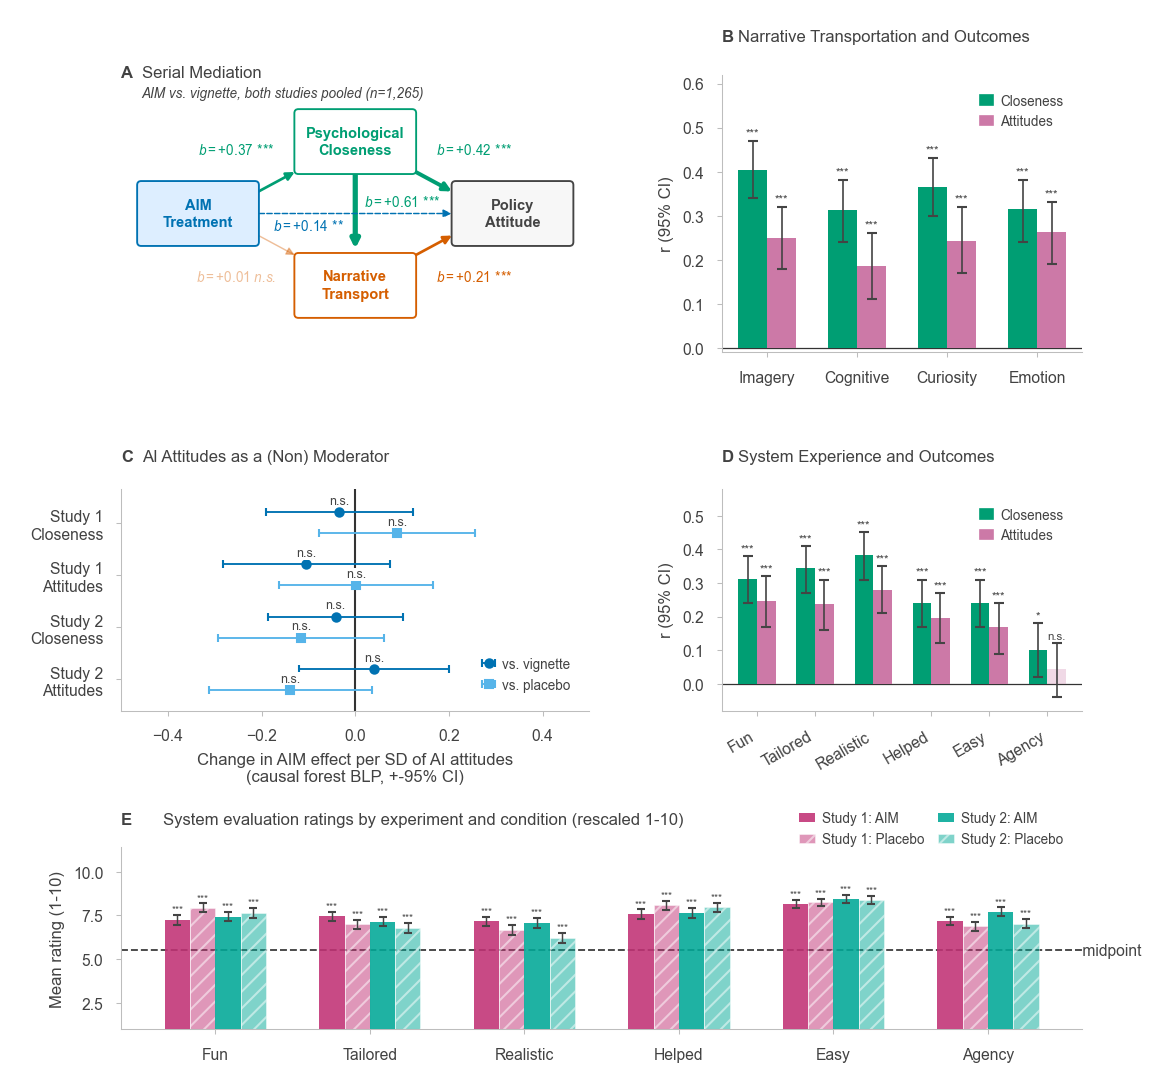

In [2]:
####################
# Section 7: Mechanisms figure — Science Magazine style (5 panels)
# Panel A β values computed live from the pingouin mediation model (Section 6)
# Wong (2011) colorblind-safe palette
####################

import sys
import pandas as pd, numpy as np, statsmodels.formula.api as smf, warnings
import matplotlib.pyplot as plt, matplotlib.gridspec as mgs
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from sklearn.preprocessing import StandardScaler
import pingouin as pg
from pathlib import Path
import importlib.util

sys.path.insert(0, 'study_comparison')
import plot_mediation_paths as pmp

helper_spec = importlib.util.spec_from_file_location("mechanism_helpers", "satellite/helpers.py")
_helpers = importlib.util.module_from_spec(helper_spec)
helper_spec.loader.exec_module(_helpers)
make_aesthetic = _helpers.make_aesthetic
warnings.filterwarnings('ignore')

import matplotlib as _mpl, seaborn as _sns
_mpl.rcParams.update(_mpl.rcParamsDefault)  # undo any make_aesthetic() / sns.set() from earlier cells
_sns.reset_orig()

BLUE='#0072B2'; TEAL='#009E73'; MAG='#CC79A7'
ORANGE='#E69F00'; SKY='#56B4E9'
LGRAY='#CCCCCC'; DGRAY='#444444'
make_aesthetic(hex_palette='wong', smallest_font_size=8, with_ticks=True)
plt.rcParams['figure.constrained_layout.use'] = False
C={'treat':BLUE,'close':TEAL,'attit':MAG,'st1':'#C13174','st2':'#00A896','node_fill':'#DDEEFF'}
FS=8.0; FST=7.5; FSN=7.5; FSA=6.5; FSL=6.5; FSC=5.5

plt.rcParams['figure.dpi'] = 150  # Jupyter inline default is 72 — too small for this figure
plt.rcParams.update({'font.family':'Arial','font.size':FS,'axes.linewidth':0.5,
    'xtick.major.width':0.5,'ytick.major.width':0.5,
    'xtick.major.size':2.5,'ytick.major.size':2.5})

def panel_title(ax, letter, text, subtitle=None):
    ax.text(0,1.11,letter,transform=ax.transAxes,fontsize=FS,fontweight='bold',va='bottom',ha='left')
    ax.text(0.044,1.11,text,transform=ax.transAxes,fontsize=FS,fontweight='normal',va='bottom',ha='left')
    if subtitle:
        ax.text(0.044,1.02,subtitle,transform=ax.transAxes,fontsize=6.5,
                va='bottom',ha='left',color=DGRAY,style='italic')

# --- Load & prep ---
sat = pd.read_csv('satellite/data/clean/analysis_data.csv').copy()
sf  = pd.read_csv('sci_fund_real/data/clean/analysis_data.csv').copy()
sat['study']=0; sf['study']=1
for df in [sat,sf]:
    for c in df.columns:
        if c.startswith('sys_'): df[c] = df[c].apply(_helpers.extract_first_number)
        if c not in ['treat_status','study','placebo_type']: df[c]=pd.to_numeric(df[c],errors='coerce')
merged=pd.concat([sat,sf],ignore_index=True)
# attitude_index and closeness_index are already z-scored within study. transport_index
# is the raw 1-7 instrument, identical in both studies, so we z-score it within study too
# rather than rescaling all three on the pooled sample, which would overwrite the
# within-study standardisation the indices already carry.
merged['transport_index']=merged.groupby('study')['transport_index'].transform(
    lambda s:(s-s.mean())/s.std())
def zs(s): m=s.mean(); sd=s.std(); return (s-m)/sd if sd>0 else s
treat=merged[merged['treat_status']=='treat'].copy()

# --- Panel A mediation: serial multiple-mediator model, AIM vs. vignette, both studies pooled ---
# Fit by 1_run_mediation_analyses.R; this reads the cached result rather than refitting. Closeness
# predicts transportation, and both predict attitudes. Placebo participants rated transportation
# for an unrelated story, so the vignette is the only control for which the transportation path
# has a clear interpretation (SI: Mediation Model Selection).
panel_a_estimates, panel_a_counts = pmp.load_estimates()
panel_a_paths = pmp.model_paths(panel_a_estimates, 'Pooled', 'Vignette', 'serial')
panel_a_n = panel_a_counts['Pooled', 'Vignette']

def stars(p):
    return '***' if p<.001 else('**' if p<.01 else('*' if p<.05 else 'n.s.'))

# --- Panels B-E data ---
TRANS=[('t1_could_pic_self','Imagery'),('t2_mentally_involved','Cognitive'),
       ('t3_wanted_to_learn','Curiosity'),('t4_affected_emo','Emotion')]
def pearson_r(sub,x,y):
    """Pearson correlation of x and y with its 95% CI (pingouin)."""
    c=pg.corr(sub[x],sub[y]).iloc[0]
    return {'r':c['r'],'lo':c['CI95%'][0],'hi':c['CI95%'][1],'p':c['p-val'],'n':int(c['n'])}

pan_b=[]
for tcol,tlabel in TRANS:
    for ocol,olabel in [('closeness_index','Closeness'),('attitude_index','Attitudes')]:
        pan_b.append({'trans':tlabel,'outcome':olabel,**pearson_r(treat[[tcol,ocol]].dropna(),tcol,ocol)})

adopt_cols=['ac_acceptance_rate','ac_accepted','ac_prop_ai_words']
treat_adopt=treat[adopt_cols+['attitude_index','closeness_index','study']].dropna().copy()
treat_adopt['ai_adopt'] = _helpers.icw_index([treat_adopt[c].to_numpy() for c in adopt_cols])
pan_c=[]
for col,label in [('closeness_index','Psychological\nCloseness'),('attitude_index','Policy\nAttitudes')]:
    sub=treat_adopt[['ai_adopt',col,'study']].dropna()
    fit=smf.ols(f'{col} ~ ai_adopt + study',data=sub).fit(cov_type='HC1')
    pan_c.append({'label':label,'beta':fit.params['ai_adopt'],'se':fit.bse['ai_adopt'],'p':fit.pvalues['ai_adopt']})

# Panel C: AI-attitude coefficient from each causal forest's best linear projection
BLP_COMPARISONS=[('vignette','vs. vignette',BLUE),('placebo','vs. placebo',SKY)]
pan_c_ai=pd.concat([pd.read_csv(f'{folder}/tables/{folder}_causal_forest_blp.csv').assign(study=sname)
                    for folder,sname in [('sci_fund_real','Study 1'),('satellite','Study 2')]])
pan_c_ai=pan_c_ai[pan_c_ai['term']=='ai_attitude_index'].replace({'outcome':{'closeness_index':'Closeness','attitude_index':'Attitudes'}})

UX=[('sys_fun','Fun'),('sys_tailored','Tailored'),('sys_realistic','Realistic'),
    ('sys_helped','Helped'),('sys_easy','Ease'),('sys_agency_1','Agency')]
pan_d=[]
for col,label in UX:
    for ocol,olabel in [('closeness_index','Closeness'),('attitude_index','Attitudes')]:
        pan_d.append({'ux':label,'outcome':olabel,**pearson_r(treat[[col,ocol]].dropna(),col,ocol)})

SYS_VARS=[('sys_fun','Fun',1,7),('sys_tailored','Tailored',1,7),
          ('sys_realistic','Realistic',1,7),('sys_helped','Helped',1,7),
          ('sys_easy','Easy',1,5),('sys_agency_1','Agency',-3,3)]
pan_e=[]
for col,label,lo,hi in SYS_VARS:
    for study_id,sname in [(0,'Cybersecurity'),(1,'Science Funding')]:
        for arm in ['treat','placebo']:
            sub=merged[(merged['treat_status']==arm)&(merged['study']==study_id)]
            vals=pd.to_numeric(sub[col],errors='coerce').dropna()
            if len(vals)==0: continue
            scaled=(vals-lo)/(hi-lo)*9+1
            pan_e.append({'var':label,'study':sname,'arm':arm,'mean':scaled.mean(),'se':scaled.sem(),
                          'p':pg.ttest(scaled.to_numpy(),5.5)['p-val'].iloc[0]})  # vs. scale midpoint

# --- Figure ---
BW=3.6; BH=1.8
fig=plt.figure(figsize=(7.2,7.4))
gs=mgs.GridSpec(3,2,figure=fig,
    width_ratios=[1.3,1.0],height_ratios=[1.25,1.0,0.82],
    wspace=0.32,hspace=0.6,left=0.08,right=0.97,top=0.94,bottom=0.08)

ax_a=fig.add_subplot(gs[0,0])
pmp.draw(ax_a, panel_a_paths, letter='A', title='Serial Mediation',
         subtitle=f'AIM vs. vignette, both studies pooled (n={panel_a_n:,})')

ax_b=fig.add_subplot(gs[0,1])
panel_title(ax_b,'B','Narrative Transportation and Outcomes')
x=np.arange(4); bw_b=0.32
for i,(outcome,ocol) in enumerate([('Closeness',C['close']),('Attitudes',C['attit'])]):
    rows=[r for r in pan_b if r['outcome']==outcome]
    rv=np.array([r['r'] for r in rows]); lo=np.array([r['lo'] for r in rows]); hi=np.array([r['hi'] for r in rows]); pv=[r['p'] for r in rows]
    off=(i-0.5)*bw_b
    for xi,v,p in zip(x+off,rv,pv):
        ax_b.bar(xi,v,width=bw_b,color=ocol,edgecolor='none',alpha=1.0 if p<.05 else 0.28,zorder=3)
    ax_b.errorbar(x+off,rv,yerr=[rv-lo,hi-rv],fmt='none',ecolor=DGRAY,capsize=2.5,lw=0.8,zorder=4)
    for xi,h,p in zip(x+off,hi,pv):
        ax_b.text(xi,h+0.008,stars(p),ha='center',va='bottom',fontsize=FSC,color=DGRAY)
ax_b.axhline(0,color='#333',lw=0.6)
ax_b.set_xticks(x); ax_b.set_xticklabels(['Imagery','Cognitive','Curiosity','Emotion'],fontsize=FST)
ax_b.set_ylabel('r (95% CI)',fontsize=FS); ax_b.set_ylim(-0.01,0.62)
ax_b.spines[['top','right']].set_visible(False); ax_b.tick_params(labelsize=FST)
ax_b.legend(handles=[mpatches.Patch(color=C['close'],label='Closeness'),
                     mpatches.Patch(color=C['attit'],label='Attitudes')],
            fontsize=FSL,frameon=False,loc='upper right',handlelength=1)

ax_c=fig.add_subplot(gs[1,0])
panel_title(ax_c,'C','AI Attitudes as a (Non) Moderator')
rows_c=[(st,oc) for st in ['Study 1','Study 2'] for oc in ['Closeness','Attitudes']]
y_c=np.arange(len(rows_c))[::-1]
ax_c.axvline(0,color='#333',lw=1.0,zorder=1)
for gi,((ctrl,clabel,ccol),mk) in enumerate(zip(BLP_COMPARISONS,['o','s'])):
    sub=pan_c_ai[pan_c_ai['control']==ctrl].set_index(['study','outcome']).loc[rows_c]
    yy=y_c+(0.2-0.4*gi)
    ax_c.errorbar(sub['estimate'],yy,xerr=[sub['estimate']-sub['ci_lower'],sub['ci_upper']-sub['estimate']],
                  fmt=mk,color=ccol,ms=4,capsize=2.0,lw=0.9,label=clabel,zorder=3)
    for yi,(_,r) in zip(yy,sub.iterrows()):
        ax_c.text(r['estimate'],yi+0.1,stars(r['p']),ha='center',va='bottom',fontsize=FSC+0.5,color=DGRAY,zorder=4,
                  bbox=dict(facecolor='white',edgecolor='none',pad=0.2))
ax_c.set_xlim(-0.5,0.5); ax_c.set_ylim(-0.6,len(rows_c)-0.35)
ax_c.set_yticks(y_c); ax_c.set_yticklabels([f'{st}\n{oc}' for st,oc in rows_c],fontsize=FST)
ax_c.set_xlabel('Change in AIM effect per SD of AI attitudes\n(causal forest BLP, +-95% CI)',fontsize=FS)
ax_c.spines[['top','right']].set_visible(False); ax_c.tick_params(labelsize=FST)
ax_c.legend(fontsize=FSL,frameon=False,loc='lower right',handlelength=1)

ax_d=fig.add_subplot(gs[1,1])
panel_title(ax_d,'D','System Experience and Outcomes')
ux_labels=['Fun','Tailored','Realistic','Helped','Easy','Agency']
x_d=np.arange(len(ux_labels)); bw_d=0.32
for i,(outcome,ocol) in enumerate([('Closeness',C['close']),('Attitudes',C['attit'])]):
    rows=[r for r in pan_d if r['outcome']==outcome]
    rv=np.array([r['r'] for r in rows]); lo=np.array([r['lo'] for r in rows]); hi=np.array([r['hi'] for r in rows]); pv=[r['p'] for r in rows]
    off=(i-0.5)*bw_d
    for xi,v,p in zip(x_d+off,rv,pv):
        ax_d.bar(xi,v,width=bw_d,color=ocol,edgecolor='none',alpha=1.0 if p<.05 else 0.28,zorder=3)
    ax_d.errorbar(x_d+off,rv,yerr=[rv-lo,hi-rv],fmt='none',ecolor=DGRAY,capsize=2.5,lw=0.8,zorder=4)
    for xi,h,p in zip(x_d+off,hi,pv):
        ax_d.text(xi,h+0.008,stars(p),ha='center',va='bottom',fontsize=FSC,color=DGRAY)
ax_d.axhline(0,color='#333',lw=0.6)
ax_d.set_xticks(x_d); ax_d.set_xticklabels(ux_labels,fontsize=FST-0.5,rotation=30,ha='right')
ax_d.set_ylabel('r (95% CI)',fontsize=FS); ax_d.set_ylim(-0.08,0.58)
ax_d.spines[['top','right']].set_visible(False); ax_d.tick_params(labelsize=FST)
ax_d.legend(handles=[mpatches.Patch(color=C['close'],label='Closeness'),
                     mpatches.Patch(color=C['attit'],label='Attitudes')],
            fontsize=FSL,frameon=False,loc='upper right',handlelength=1)

ax_e=fig.add_subplot(gs[2,:])
panel_title(ax_e,'E','System evaluation ratings by experiment and condition (rescaled 1-10)')
var_labels=['Fun','Tailored','Realistic','Helped','Easy','Agency']
bw_e=0.18; group_gap=1.1
GROUPS=[
    ('Science Funding','treat',  C['st1'],False,'Study 1: AIM'),
    ('Science Funding','placebo',C['st1'],True, 'Study 1: Placebo'),
    ('Cybersecurity','treat',  C['st2'],False,'Study 2: AIM'),
    ('Cybersecurity','placebo',C['st2'],True, 'Study 2: Placebo'),
]
cx=np.arange(len(var_labels))*group_gap; offsets=[-1.5,-0.5,0.5,1.5]
for gi,(sname,arm,scol,hatch,glabel) in enumerate(GROUPS):
    means=[]; errs=[]; ps=[]
    for vl in var_labels:
        rows=[r for r in pan_e if r['var']==vl and r['study']==sname and r['arm']==arm]
        means.append(rows[0]['mean'] if rows else float('nan'))
        errs.append(rows[0]['se'] if rows else float('nan'))
        ps.append(rows[0]['p'] if rows else float('nan'))
    off=offsets[gi]*bw_e
    ax_e.bar(cx+off,means,width=bw_e,color=scol,
             edgecolor='white' if hatch else 'none',linewidth=0.4,
             alpha=0.50 if hatch else 0.88,hatch='///' if hatch else '',
             zorder=3,label=glabel)
    ax_e.errorbar(cx+off,means,yerr=1.96*np.array(errs),fmt='none',
                  ecolor=DGRAY,capsize=1.8,lw=0.7,zorder=4)
    for xi,m,se,p in zip(cx+off,means,errs,ps):
        ax_e.text(xi,m+1.96*se+0.1,stars(p),ha='center',va='bottom',fontsize=FSC-0.5,color=DGRAY)
ax_e.axhline(5.5,color='#444',lw=0.9,ls='--',zorder=2)
ax_e.text(cx[-1]+0.64,5.5,' midpoint',va='center',fontsize=7.5,color='#444')
ax_e.set_xticks(cx); ax_e.set_xticklabels(var_labels,fontsize=FST+0.5)
ax_e.set_ylabel('Mean rating (1-10)',fontsize=FS); ax_e.set_ylim(1,11.4)
ax_e.spines[['top','right']].set_visible(False); ax_e.tick_params(labelsize=FST)
ax_e.legend(fontsize=FSL,frameon=False,loc='upper right',handlelength=1.2,
            ncol=2,columnspacing=1.0,bbox_to_anchor=(1.0,1.30))

# fig.text(0.5,0.009,
#     'Panels B and D: Pearson correlations, AIM arm only. Panel C: causal forest best linear projections. Panel A: serial multiple-mediator model (lavaan), AIM vs. vignette pooled. Panel E stars: one-sample t-test against the scale midpoint.',
#     ha='center',fontsize=FSC,color='#888',style='italic')
plt.savefig('study_comparison/plots/mechanisms.png', dpi=300, bbox_inches='tight')
plt.savefig('study_comparison/plots/mechanisms.pdf', bbox_inches='tight')
print('Mechanism sample sizes:', panel_a_n, len(treat), len(treat_adopt))
print(panel_a_estimates[panel_a_estimates.study.eq('Pooled') & panel_a_estimates.control.eq('Vignette')
                          & panel_a_estimates.model.eq(pmp.MODEL_NAMES['serial'])]
      [['lhs','op','rhs','label','est','ci.lower','ci.upper','pvalue']].to_string(index=False))
print(pd.DataFrame(pan_c).to_string(index=False))  # adoption index, reported in the Discussion
print(pan_c_ai[['study','control','outcome','estimate','ci_lower','ci_upper','p']].round(3).to_string(index=False))
print(f"AI-attitude BLP coefficients: {len(pan_c_ai)}, range {pan_c_ai.estimate.min():.2f} to {pan_c_ai.estimate.max():.2f}, min p = {pan_c_ai.p.min():.2f}")
for name, predictors in [('B', [v[0] for v in TRANS]), ('D', [v[0] for v in UX])]:
    for predictor in predictors:
        for outcome in ['closeness_index','attitude_index']:
            print(name, predictor, outcome, len(treat[[predictor,outcome,'study']].dropna()))
for study_id in [0,1]:
    for arm in ['treat','placebo']:
        print('E',study_id,arm,{c:int(merged.loc[(merged.study==study_id)&(merged.treat_status==arm),c].notna().sum()) for c,_,_,_ in SYS_VARS})

# Export the estimates underlying panel D for manuscript reporting.
system_associations = pd.DataFrame(pan_d)
system_associations.to_csv("study_comparison/tables/system_rating_associations.csv", index=False)
print("System-rating correlations (same as panel D):")
print(system_associations.to_string(index=False))

## Does prior AI attitude condition AIM's effects?

**Output:** `tables/ai_attitude_conditioning.csv`

Panel C reports the causal-forest projection of each effect onto prior AI attitude, which asks
whether the effect *varies* with that attitude. A null there does not establish that AIM worked for
participants who dislike AI, only that it worked no differently for them. This cell asks directly,
for closeness and attitudes: whether arm interacts with AI attitude, and what the effect is within
halves and within quartiles of the AI-attitude distribution.

Every estimate comes from Equation 1 fit on the relevant sample, so both AIM-minus-control effects
come from one regression rather than from separate two-arm models.


In [9]:
####################
# Section 7b: Does prior AI attitude condition AIM's effects?
####################

AI_COL = 'ai_attitude_index'            # runs 1-10, so 5.5 is the scale midpoint
AI_MIDPOINT = 5.5
COND_STUDIES = {'Study 1': sci, 'Study 2': sat}
COND_OUTCOMES = {'closeness_index': 'Closeness', 'attitude_index': 'Attitudes'}
UNFAVOURABLE, FAVOURABLE = 'Unfavourable', 'Favourable'


def arm_effects(frame, outcome, moderated=False):
    """Equation 1 on one sample: both AIM-minus-control effects from a single regression.

    When moderated, the same regression returns how each effect shifts per SD of AI attitude.
    """
    d = frame.dropna(subset=[outcome, AI_COL]).copy()
    d['is_vignette'] = (d.treat_status == 'vignette').astype(float)
    d['is_placebo'] = (d.treat_status == 'placebo').astype(float)
    d['ai_z'] = (d[AI_COL] - d[AI_COL].mean()) / d[AI_COL].std()
    rhs = '(is_vignette + is_placebo) * ai_z' if moderated else 'is_vignette + is_placebo'
    fit = smf.ols(f'{outcome} ~ {rhs}', data=d).fit(cov_type='HC1')

    rows = []
    for control in ['vignette', 'placebo']:
        term = f'is_{control}:ai_z' if moderated else f'is_{control}'
        lo, hi = fit.conf_int().loc[term]
        rows.append({'control': control, 'b': -fit.params[term], 'lo': -hi, 'hi': -lo,
                     'p': fit.pvalues[term], 'n': int(fit.nobs)})
    return rows


rows = []
for study, frame in COND_STUDIES.items():
    for outcome, label in COND_OUTCOMES.items():
        for row in arm_effects(frame, outcome, moderated=True):
            rows.append({'study': study, 'outcome': label, 'split': 'Interaction',
                         'group': 'per SD of AI attitude', 'mean_ai': np.nan, **row})
        binned = frame.assign(group=np.where(frame[AI_COL] < AI_MIDPOINT,
                                             UNFAVOURABLE, FAVOURABLE))
        for group, part in binned.groupby('group', observed=True):
            for row in arm_effects(part, outcome):
                rows.append({'study': study, 'outcome': label, 'split': 'Midpoint',
                             'group': str(group), 'mean_ai': part[AI_COL].mean(), **row})

conditioning = pd.DataFrame(rows)
conditioning.to_csv('study_comparison/tables/ai_attitude_conditioning.csv', index=False)


def show(split):
    """One block of results, formatted for reading."""
    block = conditioning[conditioning.split == split].copy()
    block['Effect [95% CI]'] = block.apply(lambda r: f'{r.b:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]', axis=1)
    block['p'] = block.p.map(lambda v: '<.001' if v < .001 else f'{v:.3f}'.lstrip('0'))
    block['AI att.'] = block.mean_ai.round(2)
    print(block[['study', 'outcome', 'control', 'group', 'n', 'AI att.',
                 'Effect [95% CI]', 'p']].to_string(index=False))


print('1. Does prior AI attitude interact with the AIM effect?')
show('Interaction')
interactions = conditioning[conditioning.split.eq('Interaction')]
print(f'   reaching p < .05: {int((interactions.p < .05).sum())} of {len(interactions)}')

print(f'\n2. AIM effect either side of the {AI_MIDPOINT} scale midpoint')
show('Midpoint')

least = conditioning[conditioning.group.eq(UNFAVOURABLE)]
print(f'\n{int((least.p < .05).sum())} of {len(least)} contrasts among participants below the '
      f'midpoint reach p < .05 (n = {least.n.min()} to {least.n.max()} per study).')


####################
# LaTeX output
####################

wide = conditioning.pivot_table(index=['study', 'outcome', 'control'], columns='group',
                                values=['b', 'lo', 'hi', 'p'], aggfunc='first')
# closeness before attitudes, vignette before placebo, as the manuscript reports them
wide = wide.reindex([(study, outcome, control)
                     for study in COND_STUDIES
                     for outcome in COND_OUTCOMES.values()
                     for control in ['vignette', 'placebo']])


def ci(row, group):
    """Estimate with its interval, for one column group."""
    return f"{row[('b', group)]:+.2f} [{row[('lo', group)]:+.2f}, {row[('hi', group)]:+.2f}]"


INTERACTION = 'per SD of AI attitude'
table = [{'Study': study, 'Outcome': outcome, 'vs.': control.title(),
          '\\shortstack{Unfavourable\\\\$b$ [95\\% CI]}': ci(row, UNFAVOURABLE),
          '\\shortstack{Favourable\\\\$b$ [95\\% CI]}': ci(row, FAVOURABLE),
          '\\shortstack{Interaction\\\\$b$ [95\\% CI]}': ci(row, INTERACTION),
          '$p$': '<.001' if row[('p', INTERACTION)] < .001 else f"{row[('p', INTERACTION)]:.3f}".lstrip('0')}
         for (study, outcome, control), row in wide.iterrows()]

caption = (
    "AIM's effects by prior attitude toward AI, split at the midpoint of the 1--10 AI-attitude "
    "scale. Estimates are AIM-minus-control differences in outcome SDs with HC1 confidence "
    "intervals. Interaction is the arm by AI-attitude term, in SDs per SD of AI attitude."
)
pd.DataFrame(table).to_latex('study_comparison/tables/ai_attitude.tex', index=False,
                             escape=False, caption=caption, label='tab:ai_attitude',
                             position='H', column_format='lllccc' + 'c')
print('\nwrote study_comparison/tables/ai_attitude.tex')


1. Does prior AI attitude interact with the AIM effect?
  study   outcome  control                 group    n  AI att.      Effect [95% CI]    p
Study 1 Closeness vignette per SD of AI attitude 1007      NaN -0.08 [-0.22, +0.05] .229
Study 1 Closeness  placebo per SD of AI attitude 1007      NaN +0.05 [-0.10, +0.21] .494
Study 1 Attitudes vignette per SD of AI attitude 1007      NaN -0.10 [-0.26, +0.06] .209
Study 1 Attitudes  placebo per SD of AI attitude 1007      NaN -0.02 [-0.17, +0.13] .785
Study 2 Closeness vignette per SD of AI attitude  894      NaN -0.05 [-0.19, +0.09] .475
Study 2 Closeness  placebo per SD of AI attitude  894      NaN -0.14 [-0.30, +0.02] .093
Study 2 Attitudes vignette per SD of AI attitude  894      NaN -0.01 [-0.15, +0.14] .945
Study 2 Attitudes  placebo per SD of AI attitude  894      NaN -0.15 [-0.30, +0.00] .053
   reaching p < .05: 0 of 8

2. AIM effect either side of the 5.5 scale midpoint
  study   outcome  control        group   n  AI att.      Effe

## Mediation sensitivity (Supplementary)

**Output:** `mediation_sensitivity.pdf`, `mediation_sensitivity.csv`

**Computation:** Imai, Keele and Yamamoto sensitivity of each preregistered mediation model to mediator-outcome confounding, fit in R by `mediation_sensitivity.R` (`mediation::mediate` and `mediation::medsens`, 1,000 simulations). This cell plots the tables it writes.

In [10]:
"""
Author: Joshua Ashkinaze
Description: Draws the sensitivity of the four preregistered mediation models (closeness as
mediator, AIM versus vignette and versus placebo, in each study) to unmeasured mediator-outcome
confounding. This cell first runs mediation_sensitivity.R, which fits mediation::mediate and
mediation::medsens, so the tables are current, then plots them. rho is the correlation between the mediator and outcome error terms;
sequential ignorability assumes rho = 0, and rho* is the value at which the average causal
mediation effect (ACME) is zero.

Inputs:
    - study_comparison/mediation_sensitivity.R, run here; it writes the two tables below from
      both studies' clean data
    - study_comparison/tables/mediation_sensitivity.csv: ACME and rho* for each model
    - study_comparison/tables/mediation_sensitivity_curves.csv: ACME and 95% interval by rho

Outputs:
    - study_comparison/plots/mediation_sensitivity.pdf: ACME as a function of rho, with 95% intervals
"""

import subprocess
import warnings
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt

_hs = importlib.util.spec_from_file_location("helpers", "src/helpers.py")
H = importlib.util.module_from_spec(_hs); _hs.loader.exec_module(H)
warnings.filterwarnings("ignore")

STUDY_COLORS = {"Study 1": '#C13174', "Study 2": '#00A896'}
DGRAY, LGRAY = '#444444', '#CCCCCC'

###############
# Plotting functions
###############

def plot_sensitivity(est, curves, outfile):
    H.make_aesthetic()
    fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True)
    for (i, study), (j, ctrl) in [(a, b) for a in enumerate(["Study 1", "Study 2"])
                                  for b in enumerate(["vignette", "placebo"])]:
        ax, col = axes[i, j], STUDY_COLORS[study]
        c = curves[(study, ctrl)].query("abs(rho) <= 0.9")   # ACME diverges as |rho| -> 1
        r = est[(est.study == study) & (est.control == ctrl)].iloc[0]
        ax.fill_between(c.rho, c.lo, c.hi, color=col, alpha=.2, linewidth=0)
        ax.plot(c.rho, c.acme, color=col, linewidth=2)
        ax.axhline(0, color=DGRAY, linewidth=1.2)
        ax.axvline(0, color=LGRAY, linewidth=1.2, linestyle=":")
        ax.plot(r.rho_star, 0, "o", color=col, markersize=7, zorder=5)
        ax.annotate(f"ρ* = {r.rho_star:.2f}", (r.rho_star, 0), xytext=(6, 8), textcoords="offset points", color=col)
        ax.set_title(f"{study}, AIM vs {ctrl}")
    fig.supxlabel("ρ, correlation between mediator and outcome errors")
    fig.supylabel("Average causal mediation effect (SD)")
    fig.savefig(outfile, bbox_inches="tight", transparent=True)
    print("saved", outfile)

###############
# Apply
###############

# Refit first, so the tables always match the current clean data
subprocess.run(["Rscript", "study_comparison/mediation_sensitivity.R"], check=True)

est = pd.read_csv("study_comparison/tables/mediation_sensitivity.csv")
curve_table = pd.read_csv("study_comparison/tables/mediation_sensitivity_curves.csv")
curves = {key: group.drop(columns=["study", "control"]) for key, group in curve_table.groupby(["study", "control"])}
plot_sensitivity(est, curves, "study_comparison/plots/mediation_sensitivity.pdf")
print(est.to_string(index=False, float_format="%.3f"))


Wrote mediation sensitivity tables to /Users/jashkina/Documents/locresearch/LocResearch/asif_studies/study_comparison/tables 
   study  control   n      acme   acme_lo   acme_hi rho_star R2star_prod
 Study 1 vignette 664 0.1681129 0.1035353 0.2394554     0.40      0.1600
 Study 1  placebo 676 0.3261065 0.2476701 0.4112403     0.40      0.1600
 Study 2 vignette 601 0.2366822 0.1522923 0.3296115     0.56      0.3136
 Study 2  placebo 591 0.5427898 0.4341822 0.6554630     0.62      0.3844
 R2tilde_prod
    0.1281871
    0.1138545
    0.1884021
    0.1716581
saved study_comparison/plots/mediation_sensitivity.pdf
  study  control   n  acme  acme_lo  acme_hi  rho_star  R2star_prod  R2tilde_prod
Study 1 vignette 664 0.168    0.104    0.239     0.400        0.160         0.128
Study 1  placebo 676 0.326    0.248    0.411     0.400        0.160         0.114
Study 2 vignette 601 0.237    0.152    0.330     0.560        0.314         0.188
Study 2  placebo 591 0.543    0.434    0.655     0.620  

# Human and AI language

**Outputs:** `linguistic_keyness_comparison.pdf`, `linguistic_features_comparison.pdf`, `linguistic_classifier.tex`. Also prints the number of suggestions shown and accepted, and the cross-study correlation of the human-AI feature profiles.

**Inputs:** each study's `human_ai_keyness.csv`, `linguistic_features.csv` and `linguistic_cv.csv`.

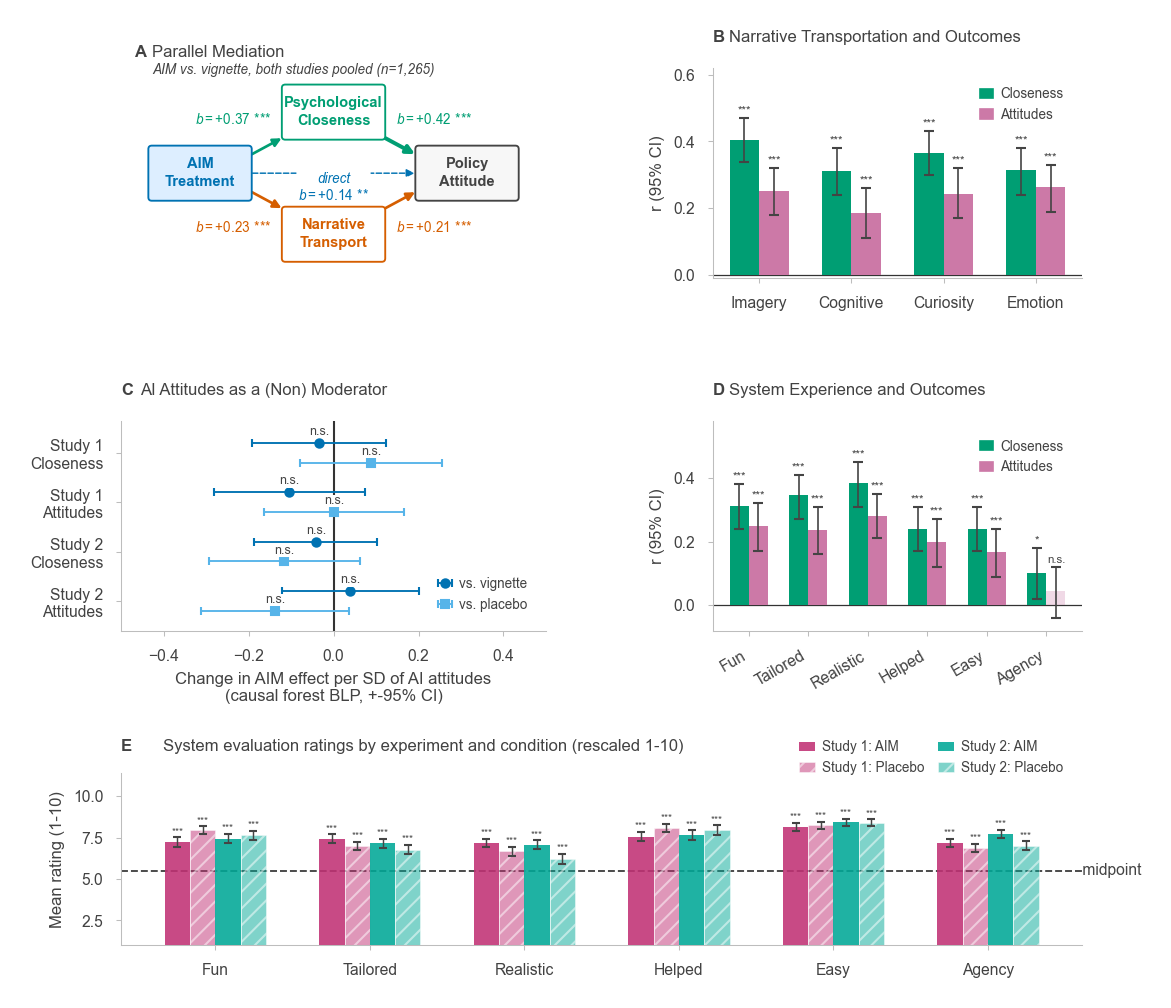

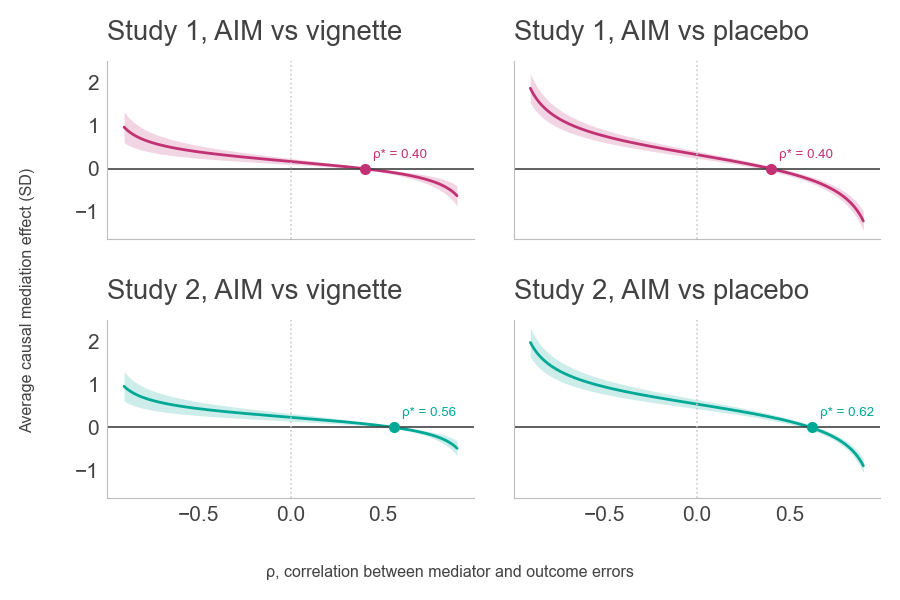

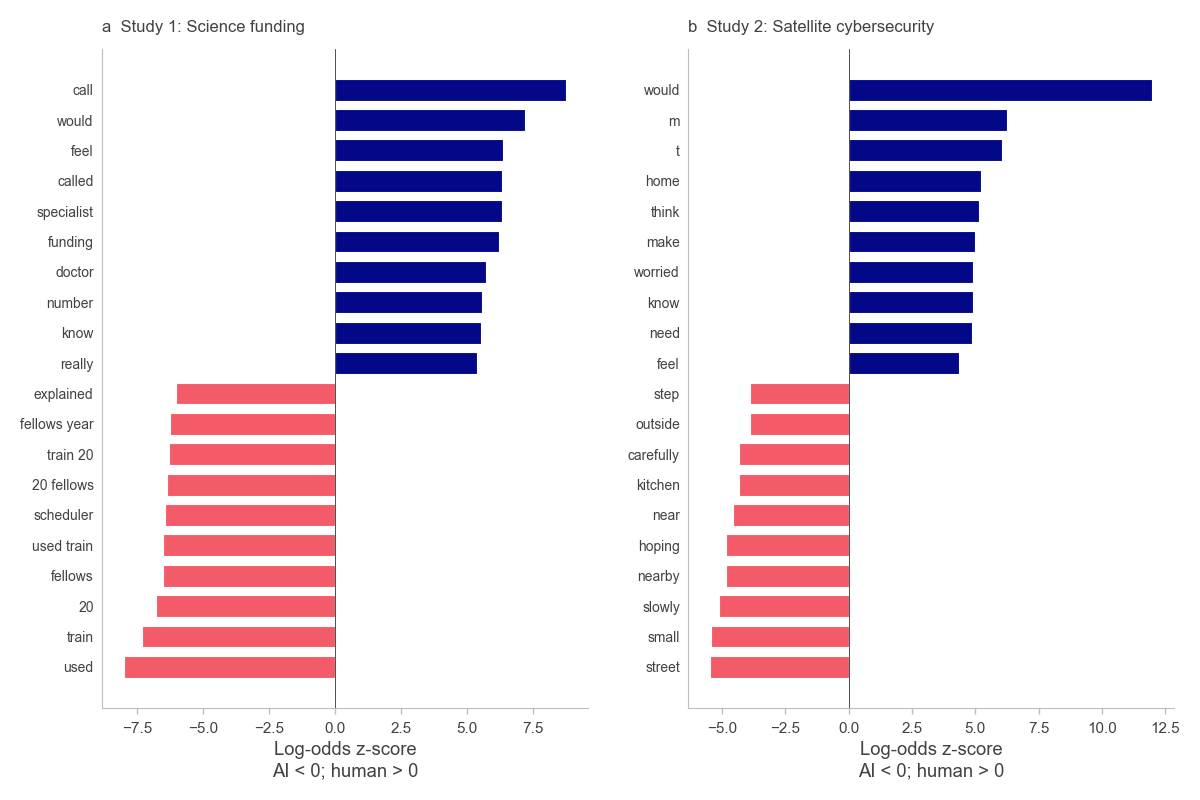

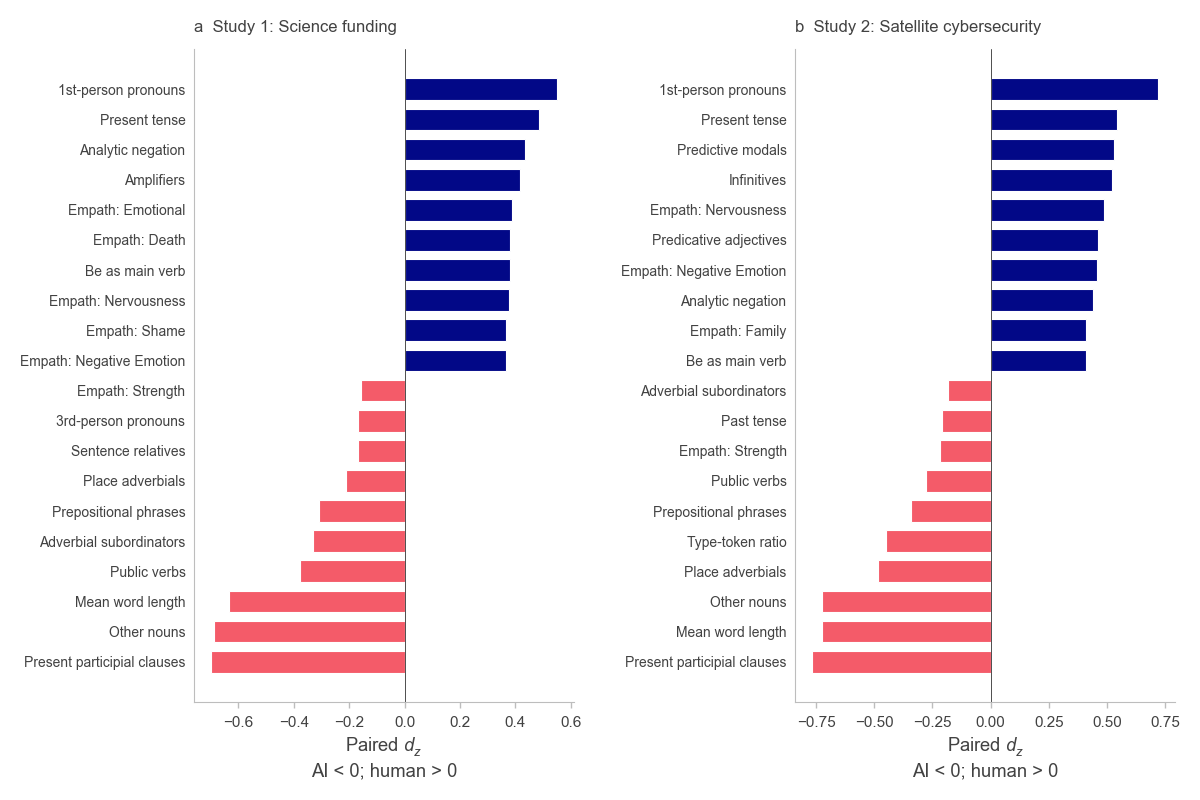

AIM participants received 23,496 suggestions and accepted 4,068
Cross-study human-AI profile: r = 0.783, rho = 0.664, same sign for 83 of 109 features
          Study  Pairs Mean AUC (SD)
Science funding    285 0.914 (0.026)
      Satellite    259 0.940 (0.028)


In [11]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Compare matched linguistic analyses from the two study notebooks.

Inputs:
- study_comparison/tables/sci_fund_real_* linguistic exports.
- study_comparison/tables/satellite_* linguistic exports.

Outputs:
- study_comparison/plots/linguistic_keyness_comparison.pdf
- study_comparison/plots/linguistic_features_comparison.pdf
- study_comparison/tables/linguistic_classifier.tex
"""
from pathlib import Path
import sys
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path("satellite").resolve()))
from helpers import make_aesthetic

TABLE_DIR = Path("study_comparison/tables")
FIGURE_DIR = Path("study_comparison/plots")
FIGURE_SIZE = (12, 8)
EXTREME_TERMS = 10
STUDY_LABELS = [("sci_fund_real", "a  Study 1: Science funding"),
                ("satellite", "b  Study 2: Satellite cybersecurity")]
AUTHOR_COLORS = {"human": "#020887", "ai": "#F45B69"}

def comparative_linguistic_plot(file_suffix, value_col, term_col, output_name, xlabel):
    """Plot the same number of extreme terms for each study."""
    make_aesthetic(smallest_font_size=11, with_ticks=True)
    fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE, layout="constrained")
    for ax, (study, label) in zip(axes, STUDY_LABELS):
        table = pd.read_csv(Path(study) / "tables" / f"{study}_{file_suffix}.csv")
        selected = pd.concat([table.nsmallest(EXTREME_TERMS, value_col),
                              table.nlargest(EXTREME_TERMS, value_col)]).sort_values(value_col)
        labels = selected[term_col].str.replace("Biber: ", "", regex=False)
        labels = labels.str.replace(r" \([^)]*\)", "", regex=True)
        labels = labels.str.replace("Other adverbial subordinators", "Adverbial subordinators")
        labels = labels.map(lambda s: textwrap.fill(s, width=27))
        colors = [AUTHOR_COLORS["human"] if x > 0 else AUTHOR_COLORS["ai"] for x in selected[value_col]]
        ax.barh(np.arange(len(selected)), selected[value_col], color=colors, height=.72)
        ax.set_yticks(np.arange(len(selected)), labels)
        ax.axvline(0, color="0.3", linewidth=.7)
        ax.set_xlabel(xlabel)
        ax.set_title(label, loc="left", fontsize=12, pad=12)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="y", length=0, labelsize=10)
    fig.savefig(FIGURE_DIR / output_name, bbox_inches="tight")
    plt.show()

comparative_linguistic_plot("human_ai_keyness", "log_odds_normalized", "term",
                            "linguistic_keyness_comparison.pdf",
                            "Log-odds z-score\nAI < 0; human > 0")
comparative_linguistic_plot("linguistic_features", "d_z", "feature",
                            "linguistic_features_comparison.pdf",
                            r"Paired $d_z$" + "\nAI < 0; human > 0")
####################
# Scale of the human-AI interaction record in the AIM arm
####################
received = accepted = 0
for study, label in STUDY_LABELS:
    arm = pd.read_csv(Path(study) / "data/clean/analysis_data.csv").query("treat_status == 'treat'")
    received += int(arm.ac_received.sum()); accepted += int(arm.ac_accepted.sum())
print(f"AIM participants received {received:,} suggestions and accepted {accepted:,}")

####################
# Cross-study consistency of the human-AI profile
# The two studies share no topic, so agreement between their d_z profiles
# tests whether the stylistic division of labour replicates.
####################
profiles = {}
for study, label in STUDY_LABELS:
    values = pd.read_csv(Path(study) / "tables" / f"{study}_linguistic_features.csv")
    profiles[study] = values.set_index("feature")["d_z"]
profile_df = pd.DataFrame(profiles).dropna()
first, second = [study for study, _ in STUDY_LABELS]
pearson = profile_df[first].corr(profile_df[second])
spearman = profile_df[first].corr(profile_df[second], method="spearman")
same_sign = int(((profile_df[first] * profile_df[second]) > 0).sum())
print(f"Cross-study human-AI profile: r = {pearson:.3f}, rho = {spearman:.3f}, "
      f"same sign for {same_sign} of {len(profile_df)} features")

classifier_rows = []
for study, label in STUDY_LABELS:
    values = pd.read_csv(Path(study) / "tables" / f"{study}_linguistic_cv.csv")
    classifier_rows.append({"Study": "Science funding" if study == "sci_fund_real" else "Satellite",
                            "Pairs": int(values.n_pairs.iloc[0]),
                            "Features": int(values.n_features.iloc[0]),
                            "Mean AUC (SD)": f"{values.auc_all.mean():.3f} ({values.auc_all.std(ddof=0):.3f})"})
classifier_table = pd.DataFrame(classifier_rows)
# The feature count is read from the notebooks rather than written in, since it depends on how
# many dictionary categories were dense enough to estimate in each study.
n_features = int(classifier_table.Features.iloc[0])
assert classifier_table.Features.nunique() == 1, "both studies must score the same features"
classifier_table = classifier_table.drop(columns="Features")
classifier_table.to_latex(TABLE_DIR / "linguistic_classifier.tex", index=False,
                          caption=(rf"Human--AI text classification with all {n_features} linguistic "
                                   r"features (Biber and Empath). Mean AUC, with its SD across five "
                                   r"participant-grouped folds."),
                          label="tab:linguistic-classifier")
print(classifier_table.to_string(index=False))

In [12]:
profile_df = profile_df.reset_index()

profile_df[
    profile_df["feature"].str.contains(
        "amplifier|downtoner|emotion",
        case=False,
        na=False,
    )
]

,feature,sci_fund_real,satellite
5,Biber: Amplifiers (extremely/perfectly),0.417179,0.312904
20,Biber: Downtoners (barely/slightly),-0.118692,0.058958
75,Empath: Emotional,0.387172,0.133815
92,Empath: Negative Emotion,0.366783,0.456099
97,Empath: Positive Emotion,0.132959,0.147413


# Heterogeneous treatment effects

**Outputs:** `grf_{study}_{control}.tex` (four tables), with sharpened q-values; `grf_sharpened_q.csv`. `main.tex` includes these tables and the BLP and conditional-effect figures directly.

**Inputs:** each study's `causal_forest_blp.csv`.

In [3]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-09

Description: Export the causal-forest best-linear-projection tables, one per study and comparison, with
sharpened q-values. Each contrast (study, comparison, outcome) is one family: every moderator
coefficient in that forest, intercept excluded.

Inputs:
- Each study's causal_forest_blp.csv, generated by its main notebook.

Outputs:
- study_comparison/tables/grf_{study}_{control}.tex (four tables).
- study_comparison/tables/grf_sharpened_q.csv: every coefficient with its p and q.
"""
from pathlib import Path
import pandas as pd
from sharp_q_values import compute_q

TABLE_DIR = Path("study_comparison/tables")
STUDIES = [("sci_fund_real", "Study 1: Science funding"),
           ("satellite", "Study 2: Satellite cybersecurity")]
MODERATOR_LABELS = {
    "(Intercept)": "Intercept", "familiar": "Familiarity", "age": "Age",
    "mi_index": "Mental imagery", "iri_fa": "IRI fantasy",
    "iri_pc": "IRI perspective", "iri_pd": "IRI distress",
    "rw_journal": "Journaling frequency", "rw_write": "Writing frequency",
    "educ_num": "Education", "income_num": "Income", "ideology_num": "Ideology",
    "ai_attitude_index": "AI attitudes", "ac_received": "Completions received",
    "ac_total_words": "Story length", "ac_acceptance_rate": "Acceptance rate",
    "ac_prop_ai_words": "Proportion AI words", "gender_Male": "Male",
}

def q_latex(q):
    return r"$\leq.001$" if q <= .001 else f"${q:.3f}$".replace("0.", ".", 1)

all_estimates = []
for study, title in STUDIES:
    estimates = pd.read_csv(Path(study) / "tables" / f"{study}_causal_forest_blp.csv")
    moderators = estimates.term.ne("(Intercept)")
    # One family per contrast: the moderator coefficients of one forest (study, comparison, outcome)
    for _, contrast in estimates[moderators].groupby(["control", "outcome"]):
        estimates.loc[contrast.index, "q"] = compute_q(contrast["p"].values)
    all_estimates.append(estimates.assign(study=study))
    for control in ["placebo", "vignette"]:
        rows = estimates[estimates.control.eq(control)]
        n = int(rows.n.iloc[0])
        n_treat, n_control = int(rows.n_treat.iloc[0]), int(rows.n_control.iloc[0])
        display = []
        for term in rows.term.drop_duplicates():
            record = {"Moderator": MODERATOR_LABELS[term]}
            for outcome, label in [("closeness_index", "Closeness"), ("attitude_index", "Attitudes")]:
                row = rows[rows.term.eq(term) & rows.outcome.eq(outcome)].iloc[0]
                record[label + r" $B$ [95\% CI]"] = f"{row.estimate:.2f} [{row.ci_lower:.2f}, {row.ci_upper:.2f}]"
                record[label + r" $p$"] = table_p_latex(row.p)
                record[label + r" $q$"] = "" if term == "(Intercept)" else q_latex(row.q)
            display.append(record)
        table_name = f"grf_{study}_{control}.tex"
        caption = (f"{title}, AIM versus {control}: causal-forest best linear projections "
                   + rf"($n={n}$). Gender uses female as the reference. $q$ is the sharpened "
                   + "false-discovery-rate q-value, with the moderator coefficients of each outcome as one family.")
        latex = pd.DataFrame(display).to_latex(index=False, escape=False,
                                               column_format=">{\\raggedright\\arraybackslash}p{3.0cm}rrrrrr",
                                               caption=caption, label=f"tab:grf-{study}-{control}")
        # Seven columns: set a smaller font inside the float so the table fits the text width
        latex = latex.replace("\\begin{table}\n", "\\begin{table}\n\\footnotesize\n\\setlength{\\tabcolsep}{3pt}\n", 1)
        (TABLE_DIR / table_name).write_text(latex)

blp_q = pd.concat(all_estimates)
blp_q.to_csv(TABLE_DIR / "grf_sharpened_q.csv", index=False)
print("Wrote 4 causal-forest tables to study_comparison/tables/")
print("\nModerators with q < .05:")
print(blp_q[blp_q.q.lt(.05)][["study", "control", "outcome", "term", "estimate", "p", "q"]].round(4).to_string(index=False))
print("\nFamily sizes:", blp_q[blp_q.term.ne("(Intercept)")].groupby(["study", "control", "outcome"]).size().to_dict())

Wrote 4 causal-forest tables to study_comparison/tables/

Moderators with q < .05:
        study control         outcome     term  estimate      p     q
sci_fund_real placebo closeness_index familiar   -0.3645 0.0000 0.001
    satellite placebo closeness_index familiar   -0.2742 0.0012 0.021

Family sizes: {('satellite', 'placebo', 'attitude_index'): 17, ('satellite', 'placebo', 'closeness_index'): 17, ('satellite', 'vignette', 'attitude_index'): 13, ('satellite', 'vignette', 'closeness_index'): 13, ('sci_fund_real', 'placebo', 'attitude_index'): 17, ('sci_fund_real', 'placebo', 'closeness_index'): 17, ('sci_fund_real', 'vignette', 'attitude_index'): 13, ('sci_fund_real', 'vignette', 'closeness_index'): 13}


# Misc system statistics

In [14]:
df

,StartDate,EndDate,Status,Progress,Duration (in seconds),Finished,RecordedDate,ResponseId,DistributionChannel,UserLanguage,...,gender_male,low_knowledge,ac_received,ac_accepted,ac_rejected,ac_acceptance_rate,ac_total_words,ac_ai_words,ac_prop_ai_words,study
0,NaN,NaN,NaN,100,697,True,NaN,NaN,NaN,NaN,...,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,NaN,NaN,NaN,100,406,True,NaN,NaN,NaN,NaN,...,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,NaN,NaN,NaN,100,529,True,NaN,NaN,NaN,NaN,...,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,NaN,NaN,NaN,100,520,True,NaN,NaN,NaN,NaN,...,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,NaN,NaN,NaN,100,471,True,NaN,NaN,NaN,NaN,...,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1002,NaN,NaN,NaN,100,1153,True,NaN,NaN,NaN,NaN,...,1.0,1,9.0,3.0,5.0,33.33,96.0,48.0,0.5000,1
1003,NaN,NaN,NaN,100,1093,True,NaN,NaN,NaN,NaN,...,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1004,NaN,NaN,NaN,100,545,True,NaN,NaN,NaN,NaN,...,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1005,NaN,NaN,NaN,100,1877,True,NaN,NaN,NaN,NaN,...,1.0,1,23.0,7.0,16.0,30.43,201.0,144.0,0.7164,1


# Autocomplete helpfulness (AIM arm)

**Computation:** the share of AIM participants who agreed that the writing assistant's suggestions helped them continue the story (`sys_helped`, 1-7; 5-7 counts as agreement), with Wilson 95% intervals, and the pretreatment measures that correlate with the rating. Correlations are Spearman rank correlations on the raw scores, pooled across the two studies (both measured the same items), with sharpened q-values across the 13 pretreatment measures.

In [34]:
"""
Author: Joshua Ashkinaze

Description: What share of AIM participants said the autocomplete helped, and which pretreatment
measures correlate with that rating (Spearman, pooled across studies). sys_helped is "The writing assistant suggestions helped me
continue the story" on a 1-7 agreement scale, asked only of participants who used the app.

Inputs:
    - sci_fund_real/data/clean/analysis_data.csv: Study 1
    - satellite/data/clean/analysis_data.csv: Study 2

Outputs:
    - study_comparison/tables/autocomplete_helped_share.csv: share agreeing, by study and pooled
    - study_comparison/tables/autocomplete_helped_correlates.csv: pretreatment correlates
    - study_comparison/tables/autocomplete_helped_regression.csv: all pretreatment measures
      in one OLS model of sys_helped
"""

import numpy as np
import pandas as pd
import pingouin as pg
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint
from sharp_q_values import compute_q

STUDY_FILES = {"Study 1": "sci_fund_real/data/clean/analysis_data.csv",
               "Study 2": "satellite/data/clean/analysis_data.csv"}
AGREE_CUTOFF = 5  # 1-7 scale; 5 (somewhat agree) and above counts as agreeing
PRETREATMENT = {
    "familiar": "Familiarity with the issue", "age": "Age", "gender_male": "Male",
    "educ_num": "Education", "income_num": "Income", "ideology_num": "Ideology (1-7, conservative high)",
    "mi_index": "Mental imagery", "iri_fa": "IRI fantasy", "iri_pc": "IRI perspective-taking",
    "iri_pd": "IRI personal distress", "rw_journal": "Journaling frequency",
    "rw_write": "Creative writing frequency", "ai_attitude_index": "AI attitudes",
}

###############
# Wrangling functions
###############

def load_aim_arm():
    """AIM participants from both studies, with sys_helped as a number."""
    frames = []
    for study, path in STUDY_FILES.items():
        d = pd.read_csv(path, low_memory=False)
        d = d[d.treat_status == "treat"].copy()
        d["study"] = study
        d["helped"] = pd.to_numeric(d.sys_helped.astype(str).str.extract(r"(\d+)")[0], errors="coerce")
        frames.append(d)
    return pd.concat(frames, ignore_index=True).dropna(subset=["helped"])

###############
# Statistics functions
###############

def share_agreeing(df, label):
    """Share at or above the agreement cutoff, with a Wilson 95% interval."""
    agree = int((df.helped >= AGREE_CUTOFF).sum())
    n = len(df)
    lo, hi = proportion_confint(agree, n, method="wilson")
    return {"group": label, "n": n, "agree": agree, "pct": 100 * agree / n,
            "lo": 100 * lo, "hi": 100 * hi, "mean": df.helped.mean(), "sd": df.helped.std(),
            "pct_6_7": 100 * (df.helped >= 6).mean()}


def correlate(df):
    """Spearman correlation of each pretreatment measure with sys_helped, pooled across studies."""
    rows = []
    for column, label in PRETREATMENT.items():
        d = df[[column, "study", "helped"]].dropna()
        r = pg.corr(d[column], d["helped"], method="spearman")
        row = {"measure": label, "n": len(d), "rho": r["r"].iloc[0], "lo": r["CI95%"].iloc[0][0],
               "hi": r["CI95%"].iloc[0][1], "p": r["p-val"].iloc[0]}
        for study in STUDY_FILES:
            s = d[d.study == study]
            row[f"rho {study}"] = s[column].corr(s.helped, method="spearman")
        rows.append(row)
    out = pd.DataFrame(rows)
    out["q"] = compute_q(out.p.values)
    return out.sort_values("p").reset_index(drop=True)

def regress(df):
    """OLS of sys_helped on every pretreatment measure at once, plus a study indicator (HC1).

    Reports B per unit and per SD of each measure, so the effects are comparable in size.
    """
    d = df.assign(study2=(df.study == "Study 2").astype(int)).dropna(subset=list(PRETREATMENT))
    fit = smf.ols("helped ~ study2 + " + " + ".join(PRETREATMENT), data=d).fit(cov_type="HC1")
    ci = fit.conf_int()
    rows = []
    for column, label in PRETREATMENT.items():
        sd = d[column].std()
        rows.append({"measure": label, "B": fit.params[column], "lo": ci.loc[column, 0],
                     "hi": ci.loc[column, 1], "B_per_SD": fit.params[column] * sd,
                     "SE": fit.bse[column], "p": fit.pvalues[column]})
    out = pd.DataFrame(rows)
    out["q"] = compute_q(out.p.values)
    return out.sort_values("p").reset_index(drop=True), fit

###############
# Apply
###############

aim = load_aim_arm()
shares = pd.DataFrame([share_agreeing(aim[aim.study == s], s) for s in STUDY_FILES]
                      + [share_agreeing(aim, "Both studies")])
shares.to_csv("study_comparison/tables/autocomplete_helped_share.csv", index=False)

print("AIM participants who said the autocomplete helped (sys_helped >= 5 on 1-7):")
for r in shares.itertuples():
    print(f"  {r.group}: {r.pct:.1f}\\% ({r.agree}/{r.n}), 95\\% CI [{r.lo:.1f}, {r.hi:.1f}]; "
          f"M={r.mean:.2f} (SD={r.sd:.2f}); {r.pct_6_7:.1f}\\% rated 6-7")
table = pd.crosstab(aim.study, aim.helped >= AGREE_CUTOFF)
chi2, p, dof, _ = chi2_contingency(table, correction=False)
print(f"  Study 1 vs Study 2: chi2({dof})={chi2:.2f}, p={p:.3f}")

correlates = correlate(aim)
correlates.to_csv("study_comparison/tables/autocomplete_helped_correlates.csv", index=False)
print("\nPretreatment correlates of sys_helped (Spearman, both studies pooled):")
print(correlates.round(3).to_string(index=False))

regression, model = regress(aim)
regression.to_csv("study_comparison/tables/autocomplete_helped_regression.csv", index=False)
print(f"\nOne OLS model of sys_helped on all pretreatment measures plus study (HC1), "
      f"n={int(model.nobs)}, R2={model.rsquared:.3f}:")
print(regression.round(3).to_string(index=False))


AIM participants who said the autocomplete helped (sys_helped >= 5 on 1-7):
  Study 1: 73.0\% (243/333), 95\% CI [68.0, 77.5]; M=5.38 (SD=1.73); 56.5\% rated 6-7
  Study 2: 77.5\% (231/298), 95\% CI [72.4, 81.9]; M=5.43 (SD=1.76); 58.1\% rated 6-7
  Both studies: 75.1\% (474/631), 95\% CI [71.6, 78.3]; M=5.40 (SD=1.74); 57.2\% rated 6-7
  Study 1 vs Study 2: chi2(1)=1.74, p=0.187

Pretreatment correlates of sys_helped (Spearman, both studies pooled):
                          measure   n    rho    lo    hi     p  rho Study 1  rho Study 2     q
                     AI attitudes 631  0.334  0.26  0.40 0.000        0.301        0.368 0.001
           IRI perspective-taking 631  0.172  0.10  0.25 0.000        0.134        0.217 0.001
                      IRI fantasy 631  0.131  0.05  0.21 0.001        0.050        0.223 0.004
                              Age 629 -0.116 -0.19 -0.04 0.004       -0.119       -0.113 0.009
                   Mental imagery 631  0.091  0.01  0.17 0.022        

In [32]:
print(correlates.round(3).to_string(index=False))


                          measure   n    rho    lo    hi     p  rho Study 1  rho Study 2     q
                     AI attitudes 631  0.334  0.26  0.40 0.000        0.301        0.368 0.001
           IRI perspective-taking 631  0.172  0.10  0.25 0.000        0.134        0.217 0.001
                      IRI fantasy 631  0.131  0.05  0.21 0.001        0.050        0.223 0.004
                              Age 629 -0.116 -0.19 -0.04 0.004       -0.119       -0.113 0.009
                   Mental imagery 631  0.091  0.01  0.17 0.022        0.095        0.088 0.041
             Journaling frequency 631  0.087  0.01  0.16 0.029        0.105        0.065 0.047
Ideology (1-7, conservative high) 631  0.079  0.00  0.16 0.048        0.078        0.078 0.061
            IRI personal distress 631  0.073 -0.00  0.15 0.065        0.011        0.142 0.069
                        Education 631 -0.058 -0.14  0.02 0.145       -0.092       -0.024 0.107
                             Male 631 -0.056 -0.13